# Benchmarking financial equations

An independent model-path reference is an average of discounted terminal values:

$$
\widehat u_M(0,x_0)=\frac1M\sum_{m=1}^{M}e^{-rT}g\!\left(X_T^{(m)}\right),
\qquad
\widehat{\operatorname{SE}}\!\left(\widehat u_M\right)=\frac{s_g}{\sqrt M}.
$$

Here, $M$ is the number of independently generated terminal states; $m$ labels one model path; $r$ is the discount rate; $T$ is the final time; $g$ is the terminal value; $X_T^{(m)}$ is a generated terminal state; $s_g$ is the sample standard deviation of the discounted terminal values; and $\widehat{\operatorname{SE}}$ is the estimated simulation error of their mean.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
from pathlib import Path
import inspect
import math
import re
import sys
import time
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image

warnings.filterwarnings("ignore")
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
ROOT = Path.cwd().parents[1]

from RiskLabAI.pde import BlackScholesBarenblatt, DeepBSDE, DeepTimeSetTransformer, Equation, FBSDESolver, FBSNNNetwork, FBSNNolver, FBSNNSolver, HJBLQ, ISAB, MAB, Net1, PMA, PricingDefaultRisk, PricingDiffRate, SAB, TimeDependentNetwork, TimeDependentNetworkMonteCarlo, TimeNet, TimeNetForSet, initialize_weights

FIGURES = ROOT / "outputs" / "figures" / "29_deep_bsde"
TABLES = ROOT / "outputs" / "tables" / "29_deep_bsde"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#111827", "axes": "#111827", "text": "#E5E7EB", "cyan": "#38BDF8", "amber": "#FBBF24", "green": "#34D399", "rose": "#FB7185", "violet": "#C084FC", "grid": "#374151", "muted": "#94A3B8"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def count_parameters(model):
    return int(sum(parameter.numel() for parameter in model.parameters()))

def finite_sequence(values):
    array = np.asarray(values, dtype=float)
    return bool(array.size and np.all(np.isfinite(array)))

device = torch.device("cpu")



def layer_sizes_for(pde, method, width):
    if method == "DeepBSDE":
        return [pde.dim, width, width, pde.dim]
    return [width, width]

def run_fbsde(pde, method, seed, iterations, batch_size, width, learning_rate):
    np.random.seed(seed)
    torch.manual_seed(seed)
    solver = FBSDESolver(pde=pde, layer_sizes=layer_sizes_for(pde, method, width), learning_rate=learning_rate, solving_method=method, device=device)
    started = time.perf_counter()
    losses, estimates = solver.solve(num_iterations=iterations, batch_size=batch_size, init_y=float(pde.y_init if pde.y_init is not None else 0.0))
    elapsed = time.perf_counter() - started
    return {"losses": np.asarray(losses, dtype=float), "estimates": np.asarray(estimates, dtype=float), "seconds": elapsed, "parameters": count_parameters(solver.solver)}

def run_fbsnn(pde, seed, iterations, batch_size, width, learning_rate):
    np.random.seed(seed)
    torch.manual_seed(seed)
    solver = FBSNNSolver(pde=pde, layer_sizes=[pde.dim + 1, width, width, 1], learning_rate=learning_rate, device=device)
    dw_validation, x_validation = pde.sample(128)
    x_validation = torch.tensor(x_validation, dtype=torch.float32, device=device)
    dw_validation = torch.tensor(dw_validation, dtype=torch.float32, device=device)
    t_validation = torch.ones((128, 1), device=device)
    dummy = torch.tensor(0.0, device=device)
    losses = []
    estimates = []
    started = time.perf_counter()
    for _ in range(iterations):
        dw_training, x_training = pde.sample(batch_size)
        x_training = torch.tensor(x_training, dtype=torch.float32, device=device)
        dw_training = torch.tensor(dw_training, dtype=torch.float32, device=device)
        t_training = torch.ones((batch_size, 1), device=device)
        solver.optimizer.zero_grad()
        loss = solver.compute_loss(x_training, dw_training, t_training, dummy)
        loss.backward()
        solver.optimizer.step()
        with torch.enable_grad():
            validation_loss = solver.compute_loss(x_validation.detach(), dw_validation, t_validation, dummy)
        with torch.no_grad():
            initial_state = x_validation[:, :, 0]
            initial_time = torch.zeros((128, 1), device=device)
            initial_value = solver.solver(torch.cat((initial_time, initial_state), dim=1)).mean()
        losses.append(float(validation_loss.detach().cpu()))
        estimates.append(float(initial_value.detach().cpu()))
    elapsed = time.perf_counter() - started
    return {"losses": np.asarray(losses, dtype=float), "estimates": np.asarray(estimates, dtype=float), "seconds": elapsed, "parameters": count_parameters(solver.solver)}

def run_method(pde, method, seed, iterations, batch_size, width):
    if method == "FBSNN":
        return run_fbsnn(pde, seed, iterations, batch_size, width, 0.001)
    learning_rate = 0.005 if method == "DTNN" else 0.01
    return run_fbsde(pde, method, seed, iterations, batch_size, width, learning_rate)

def summarize_histories(histories, reference=None):
    rows = []
    for method in sorted({item["method"] for item in histories}):
        selected = [item for item in histories if item["method"] == method]
        final_values = np.array([item["estimates"][-1] for item in selected])
        final_losses = np.array([item["losses"][-1] for item in selected])
        row = {"Method": method, "Runs": len(selected), "Initial value mean": final_values.mean(), "Initial value standard deviation": final_values.std(ddof=1) if len(selected) > 1 else 0.0, "Final loss mean": final_losses.mean(), "Final loss standard deviation": final_losses.std(ddof=1) if len(selected) > 1 else 0.0, "Mean run time seconds": np.mean([item["seconds"] for item in selected]), "Parameters": selected[0]["parameters"]}
        if reference is not None and np.isfinite(reference):
            row["Absolute error"] = abs(row["Initial value mean"] - reference)
            row["Relative error"] = row["Absolute error"] / max(abs(reference), 1e-12)
        rows.append(row)
    return pd.DataFrame(rows)

def plot_method_histories(histories, reference, stem, title):
    methods = [method for method in ("DTNN", "DeepBSDE", "FBSNN") if any(item["method"] == method for item in histories)]
    colors = {"DTNN": palette["green"], "DeepBSDE": palette["cyan"], "FBSNN": palette["rose"]}
    figure, axes = plt.subplots(1, 2, figsize=(11.2, 4.1))
    for method in methods:
        selected = [item for item in histories if item["method"] == method]
        estimates = np.vstack([item["estimates"] for item in selected])
        losses = np.vstack([item["losses"] for item in selected])
        steps = np.arange(1, estimates.shape[1] + 1)
        mean_estimate = estimates.mean(axis=0)
        std_estimate = estimates.std(axis=0)
        mean_loss = losses.mean(axis=0)
        std_loss = losses.std(axis=0)
        axes[0].plot(steps, mean_estimate, color=colors[method], linewidth=1.9, label=method)
        axes[0].fill_between(steps, mean_estimate - std_estimate, mean_estimate + std_estimate, color=colors[method], alpha=0.18)
        axes[1].plot(steps, np.maximum(mean_loss, 1e-12), color=colors[method], linewidth=1.9, label=method)
        axes[1].fill_between(steps, np.maximum(mean_loss - std_loss, 1e-12), np.maximum(mean_loss + std_loss, 1e-12), color=colors[method], alpha=0.18)
    if reference is not None and np.isfinite(reference):
        axes[0].axhline(reference, color=palette["amber"], linestyle="--", linewidth=1.8, label="Reference")
    axes[0].set_xlabel("Training round")
    axes[0].set_ylabel("Initial value estimate")
    axes[0].set_title(title)
    axes[1].set_xlabel("Training round")
    axes[1].set_ylabel("Terminal loss")
    axes[1].set_yscale("log")
    axes[1].set_title("Validation loss")
    for axis in axes:
        axis.grid(True, alpha=0.45)
        axis.legend()
    figure.tight_layout()
    save_figure(figure, stem)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#111827", "axes.facecolor": "#111827", "axes.edgecolor": "#94A3B8", "axes.labelcolor": "#E5E7EB", "axes.titlecolor": "#E5E7EB", "axes.titleweight": "bold", "xtick.color": "#94A3B8", "ytick.color": "#94A3B8", "text.color": "#E5E7EB", "grid.color": "#374151", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#111827", "legend.edgecolor": "#374151", "legend.framealpha": 0.96, "savefig.facecolor": "#111827", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Seven Benchmark Families

In [2]:
class BlackScholesBarenblattMaxMin(BlackScholesBarenblatt):
    def terminal(self, t, x):
        return torch.max(x, dim=1, keepdim=True)[0] - torch.min(x, dim=1, keepdim=True)[0]

    def terminal_for_sample(self, x):
        return torch.max(x, dim=2, keepdim=True)[0] - torch.min(x, dim=2, keepdim=True)[0]

class BlackScholesBarenblattBasket(BlackScholesBarenblatt):
    def terminal(self, t, x):
        return torch.mean(x, dim=1, keepdim=True)

    def terminal_for_sample(self, x):
        return torch.mean(x, dim=2, keepdim=True)

class BlackScholesBarenblattBestOf(BlackScholesBarenblatt):
    def terminal(self, t, x):
        return torch.max(x, dim=1, keepdim=True)[0]

    def terminal_for_sample(self, x):
        return torch.max(x, dim=2, keepdim=True)[0]

benchmark_specs = [
    {"Benchmark": "Default risk", "Class": PricingDefaultRisk, "Final time": 1.0, "Initial guess": 40.0, "Reference": "No independent value used"},
    {"Benchmark": "Quadratic fixed-volatility value", "Class": BlackScholesBarenblatt, "Final time": 1.0, "Initial guess": 70.0, "Reference": "Exact formula"},
    {"Benchmark": "Maximum-minus-minimum value", "Class": BlackScholesBarenblattMaxMin, "Final time": 1.0, "Initial guess": 1.0, "Reference": "Independent model-path average"},
    {"Benchmark": "Basket value", "Class": BlackScholesBarenblattBasket, "Final time": 1.0, "Initial guess": 0.75, "Reference": "Exact formula"},
    {"Benchmark": "Best-of value", "Class": BlackScholesBarenblattBestOf, "Final time": 1.0, "Initial guess": 1.5, "Reference": "Independent model-path average"},
    {"Benchmark": "Different borrowing and lending rates", "Class": PricingDiffRate, "Final time": 0.5, "Initial guess": 20.0, "Reference": "No independent value used"},
    {"Benchmark": "Hamilton-Jacobi-Bellman", "Class": HJBLQ, "Final time": 1.0, "Initial guess": 4.0, "Reference": "Independent model-path average"},
]
design_table = pd.DataFrame([{key: value for key, value in specification.items() if key != "Class"} | {"Dimension": 100, "Time intervals": 12, "Training rounds": 24, "Repeated seeds": 2} for specification in benchmark_specs])
save_table(design_table, "benchmark_design", "The seven fresh benchmark families and their common training design.", "tab:chapter29-benchmark-design")
display(design_table)

,Benchmark,Final time,Initial guess,Reference,Dimension,Time intervals,Training rounds,Repeated seeds
0,Default risk,1,40,No independent value used,100,12,24,2
1,Quadratic fixed-volatility value,1,70,Exact formula,100,12,24,2
2,Maximum-minus-minimum value,1,1,Independent model-path average,100,12,24,2
3,Basket value,1,0.75,Exact formula,100,12,24,2
4,Best-of value,1,1.5,Independent model-path average,100,12,24,2
5,Different borrowing and lending rates,0.5,20,No independent value used,100,12,24,2
6,Hamilton-Jacobi-Bellman,1,4,Independent model-path average,100,12,24,2


## Comparing exact benchmarks with independent checks

In [3]:
def discounted_lognormal_reference(pde, payoff_name, draws, seed):
    rng = np.random.default_rng(seed)
    total = 0.0
    total_square = 0.0
    observed = 0
    for start in range(0, draws, 4000):
        count = min(4000, draws - start)
        shocks = rng.standard_normal((count, pde.dim))
        terminal = pde.x_init[None, :] * np.exp((pde.rate - 0.5 * pde.sigma**2) * pde.total_time + pde.sigma * np.sqrt(pde.total_time) * shocks)
        if payoff_name == "Maximum-minus-minimum value":
            payoff = terminal.max(axis=1) - terminal.min(axis=1)
        elif payoff_name == "Best-of value":
            payoff = terminal.max(axis=1)
        else:
            payoff = np.sum(terminal**2, axis=1)
        discounted = np.exp(-pde.rate * pde.total_time) * payoff
        total += discounted.sum()
        total_square += np.square(discounted).sum()
        observed += count
    mean = total / observed
    variance = (total_square - observed * mean**2) / (observed - 1)
    return mean, np.sqrt(variance / observed)

def hjb_reference(pde, draws, seed):
    rng = np.random.default_rng(seed)
    total = 0.0
    total_square = 0.0
    observed = 0
    for start in range(0, draws, 4000):
        count = min(4000, draws - start)
        terminal = pde.sigma * np.sqrt(pde.total_time) * rng.standard_normal((count, pde.dim))
        transformed = 2.0 / (1.0 + np.sum(terminal**2, axis=1))
        total += transformed.sum()
        total_square += np.square(transformed).sum()
        observed += count
    mean = total / observed
    variance = (total_square - observed * mean**2) / (observed - 1)
    return -np.log(mean), np.sqrt(variance / observed) / mean

reference_rows = []
reference_values = {}
for position, specification in enumerate(benchmark_specs):
    pde = specification["Class"]({"dim": 100, "total_time": specification["Final time"], "num_time_interval": 12})
    name = specification["Benchmark"]
    if name == "Quadratic fixed-volatility value":
        value = float(np.exp((pde.rate + pde.sigma**2) * pde.total_time) * np.sum(np.asarray(pde.x_init)**2))
        error = 0.0
        draws = 0
        source = "Exact formula"
    elif name == "Basket value":
        value = float(np.mean(pde.x_init))
        error = 0.0
        draws = 0
        source = "Exact formula"
    elif name in {"Maximum-minus-minimum value", "Best-of value"}:
        value, error = discounted_lognormal_reference(pde, name, 80000, 2960 + position)
        draws = 80000
        source = "Independent model-path average"
    elif name == "Hamilton-Jacobi-Bellman":
        value, error = hjb_reference(pde, 100000, 2960 + position)
        draws = 100000
        source = "Independent model-path average"
    else:
        value = np.nan
        error = np.nan
        draws = 0
        source = "No independent value used"
    reference_values[name] = value
    reference_rows.append({"Benchmark": name, "Reference source": source, "Reference value": value, "Estimated standard error": error, "Generated terminal states": draws})
reference_table = pd.DataFrame(reference_rows)
save_table(reference_table, "benchmark_references", "Exact and independently generated references used in the seven-family comparison.", "tab:chapter29-benchmark-references")
display(reference_table)

,Benchmark,Reference source,Reference value,Estimated standard error,Generated terminal states
0,Default risk,No independent value used,NaN,NaN,0
1,Quadratic fixed-volatility value,Exact formula,77.104879,0,0
2,Maximum-minus-minimum value,Independent model-path average,2.119785,0.001625,80000
3,Basket value,Exact formula,0.75,0,0
4,Best-of value,Independent model-path average,2.312507,0.001622,80000
5,Different borrowing and lending rates,No independent value used,NaN,NaN,0
6,Hamilton-Jacobi-Bellman,Independent model-path average,4.590193,0.000454,100000


## Repeated Method Comparisons

,Benchmark,Method,Seed,Final initial value,Final terminal loss,Absolute error,Relative error,Run time seconds,Parameters
0,Default risk,DTNN,17,55.131866,310.615479,NaN,NaN,0.661216,546582
1,Default risk,DTNN,43,55.063293,314.694031,NaN,NaN,0.644713,546582
2,Default risk,DeepBSDE,17,41.685158,255.240295,NaN,NaN,0.166607,47040
3,Default risk,DeepBSDE,43,42.231625,225.385269,NaN,NaN,0.171804,47040
4,Default risk,FBSNN,17,-0.132628,3681.073486,NaN,NaN,0.306762,1921
5,Default risk,FBSNN,43,0.185586,3608.849854,NaN,NaN,0.305912,1921
6,Quadratic fixed-volatility value,DTNN,17,71.066727,52.182331,6.038152,0.078311,0.638797,546582
7,Quadratic fixed-volatility value,DTNN,43,70.328125,56.329597,6.776754,0.08789,0.624942,546582
8,Quadratic fixed-volatility value,DeepBSDE,17,70.395164,51.01194,6.709714,0.087021,0.139629,47040
9,Quadratic fixed-volatility value,DeepBSDE,43,70.519897,65.402275,6.584981,0.085403,0.139921,47040


,Benchmark,Method,Runs,Initial value mean,Initial value standard deviation,Final loss mean,Final loss standard deviation,Mean run time seconds,Parameters,Absolute error,Relative error
0,Default risk,DTNN,2,55.09758,0.048488,312.654755,2.883972,0.652965,546582,NaN,NaN
1,Default risk,DeepBSDE,2,41.958391,0.38641,240.312782,21.110692,0.169205,47040,NaN,NaN
2,Default risk,FBSNN,2,0.026479,0.225011,3644.96167,51.069821,0.306337,1921,NaN,NaN
3,Quadratic fixed-volatility value,DTNN,2,70.697426,0.52227,54.255964,2.93256,0.63187,546582,6.407453,0.0831
4,Quadratic fixed-volatility value,DeepBSDE,2,70.457531,0.0882,58.207108,10.175504,0.139775,47040,6.647348,0.086212
5,Quadratic fixed-volatility value,FBSNN,2,1.022315,0.407413,5327.495361,129.982316,0.278155,1921,76.082564,0.986741
6,Maximum-minus-minimum value,DTNN,2,1.468933,0.001234,1.645731,0.323194,0.63179,546582,0.650852,0.307037
7,Maximum-minus-minimum value,DeepBSDE,2,2.162139,0.01934,0.207679,0.034205,0.148842,47040,0.042355,0.019981
8,Maximum-minus-minimum value,FBSNN,2,1.309947,0.010447,0.75933,0.035059,0.280855,1921,0.809837,0.382037
9,Basket value,DTNN,2,0.742911,0.150278,0.81066,0.108631,0.619414,546582,0.007089,0.009452


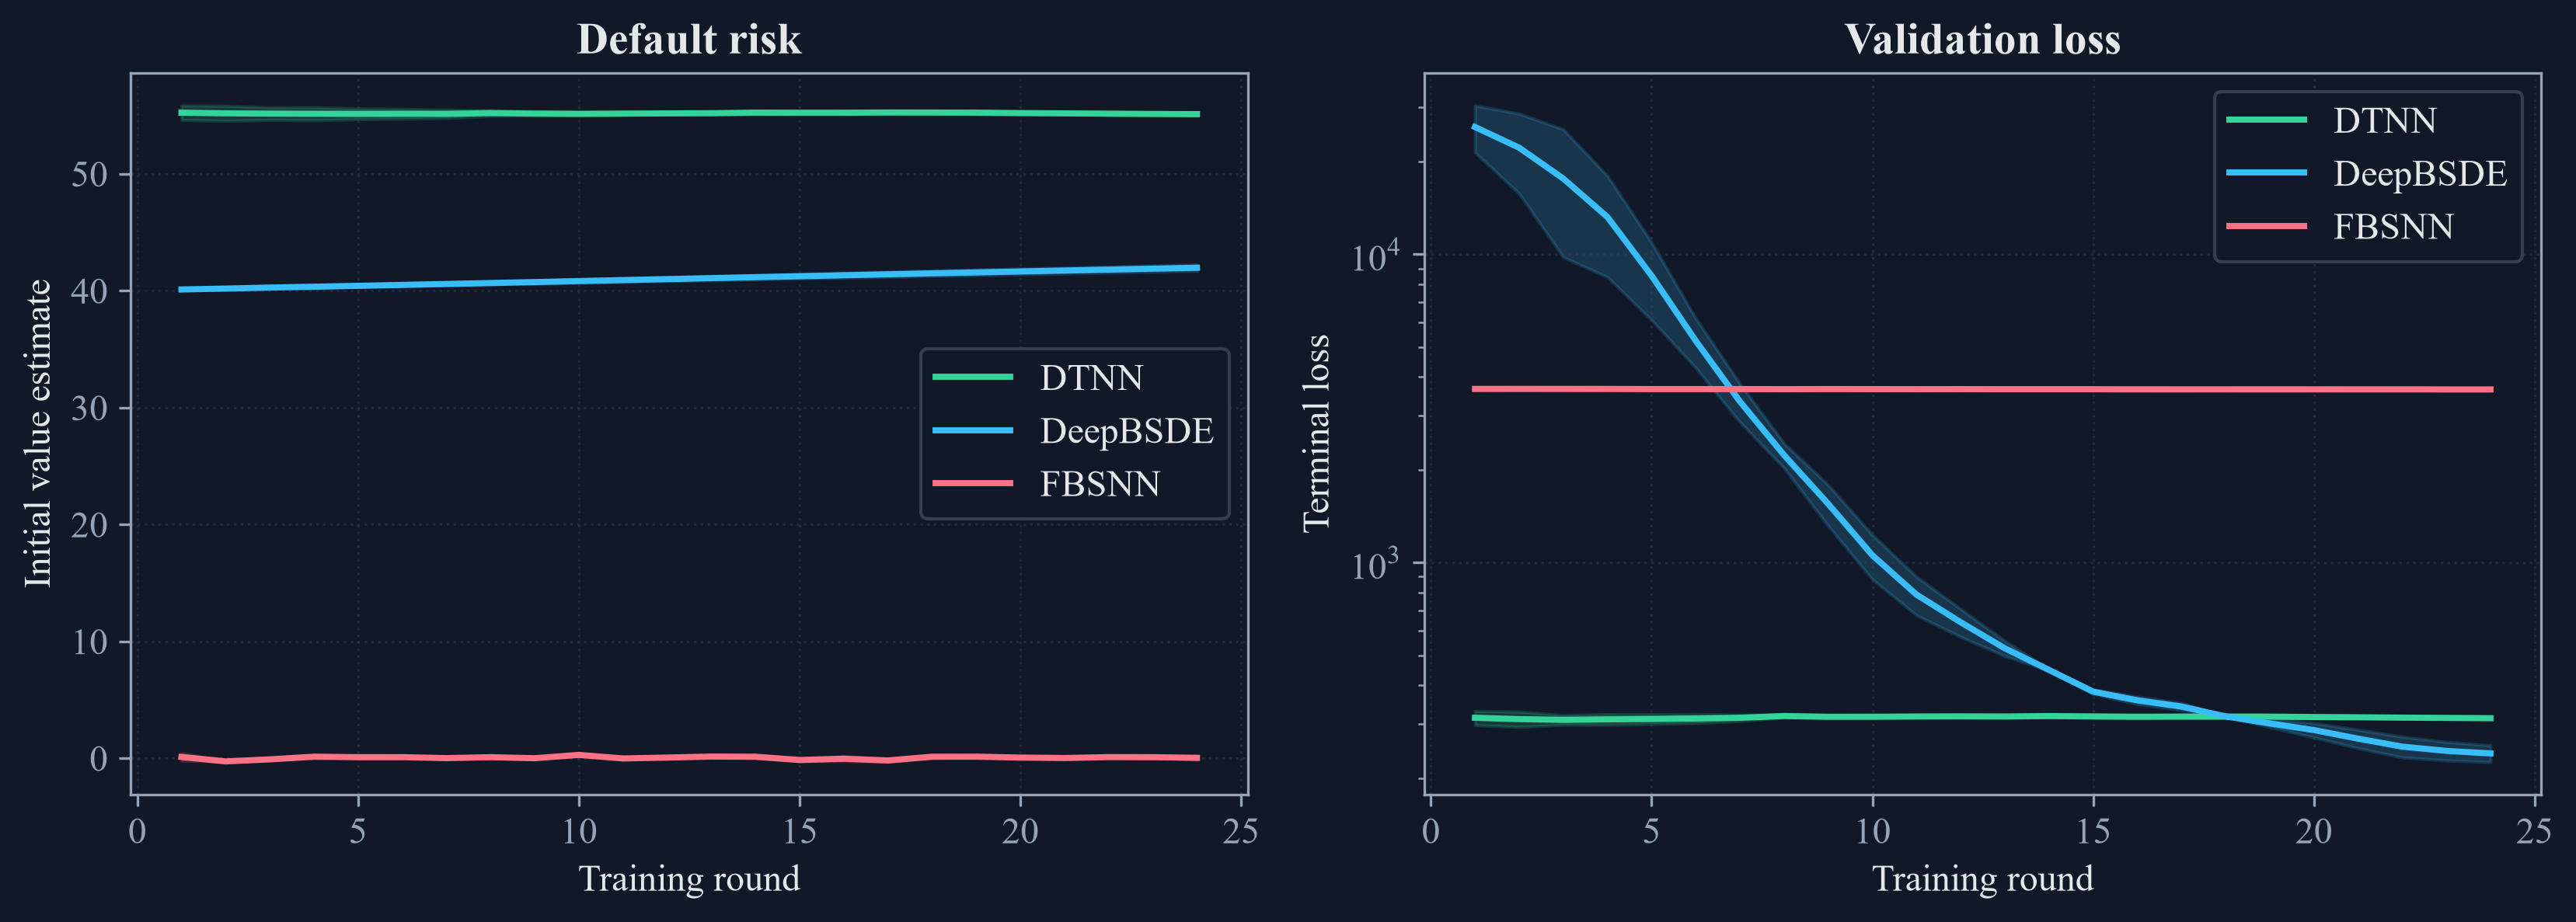

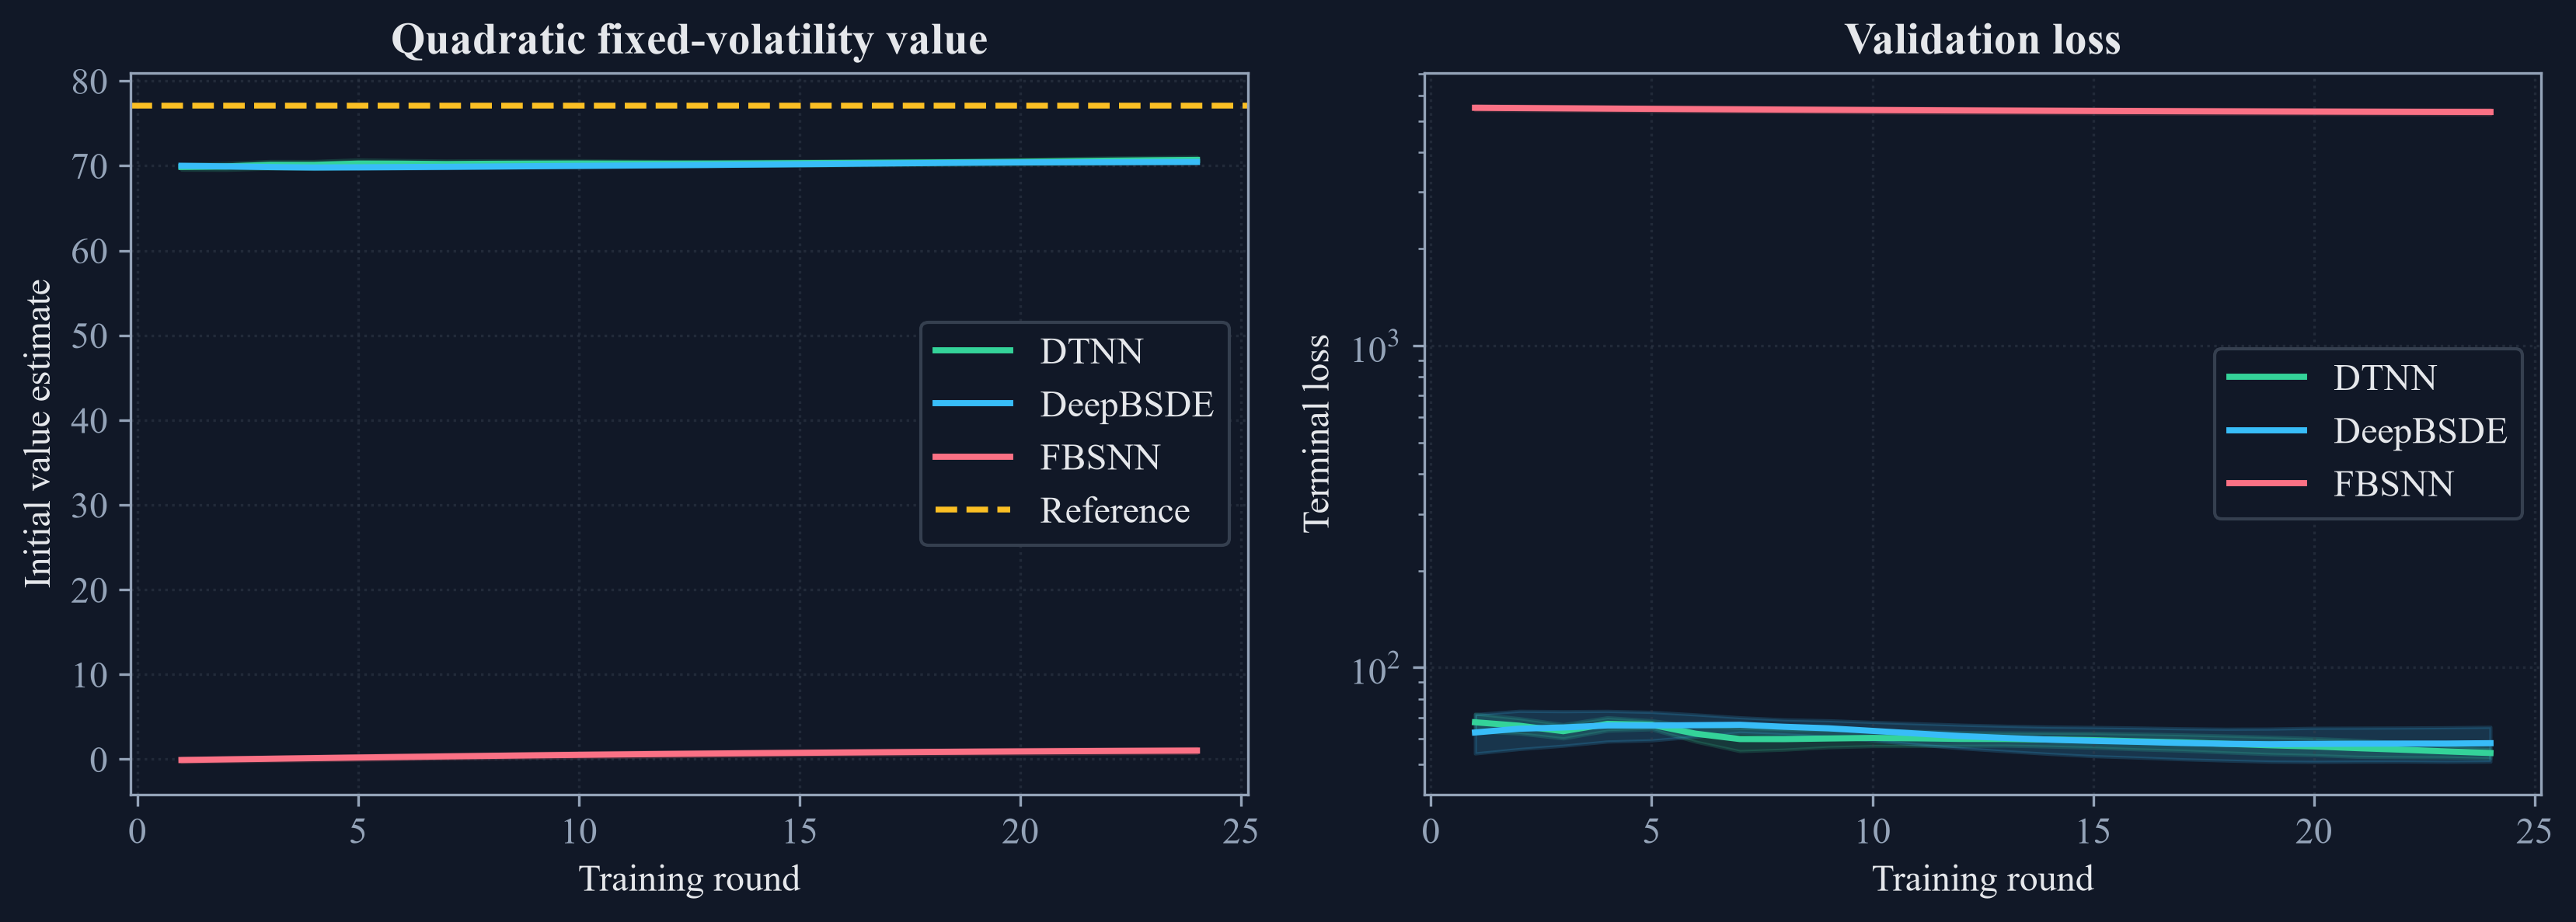

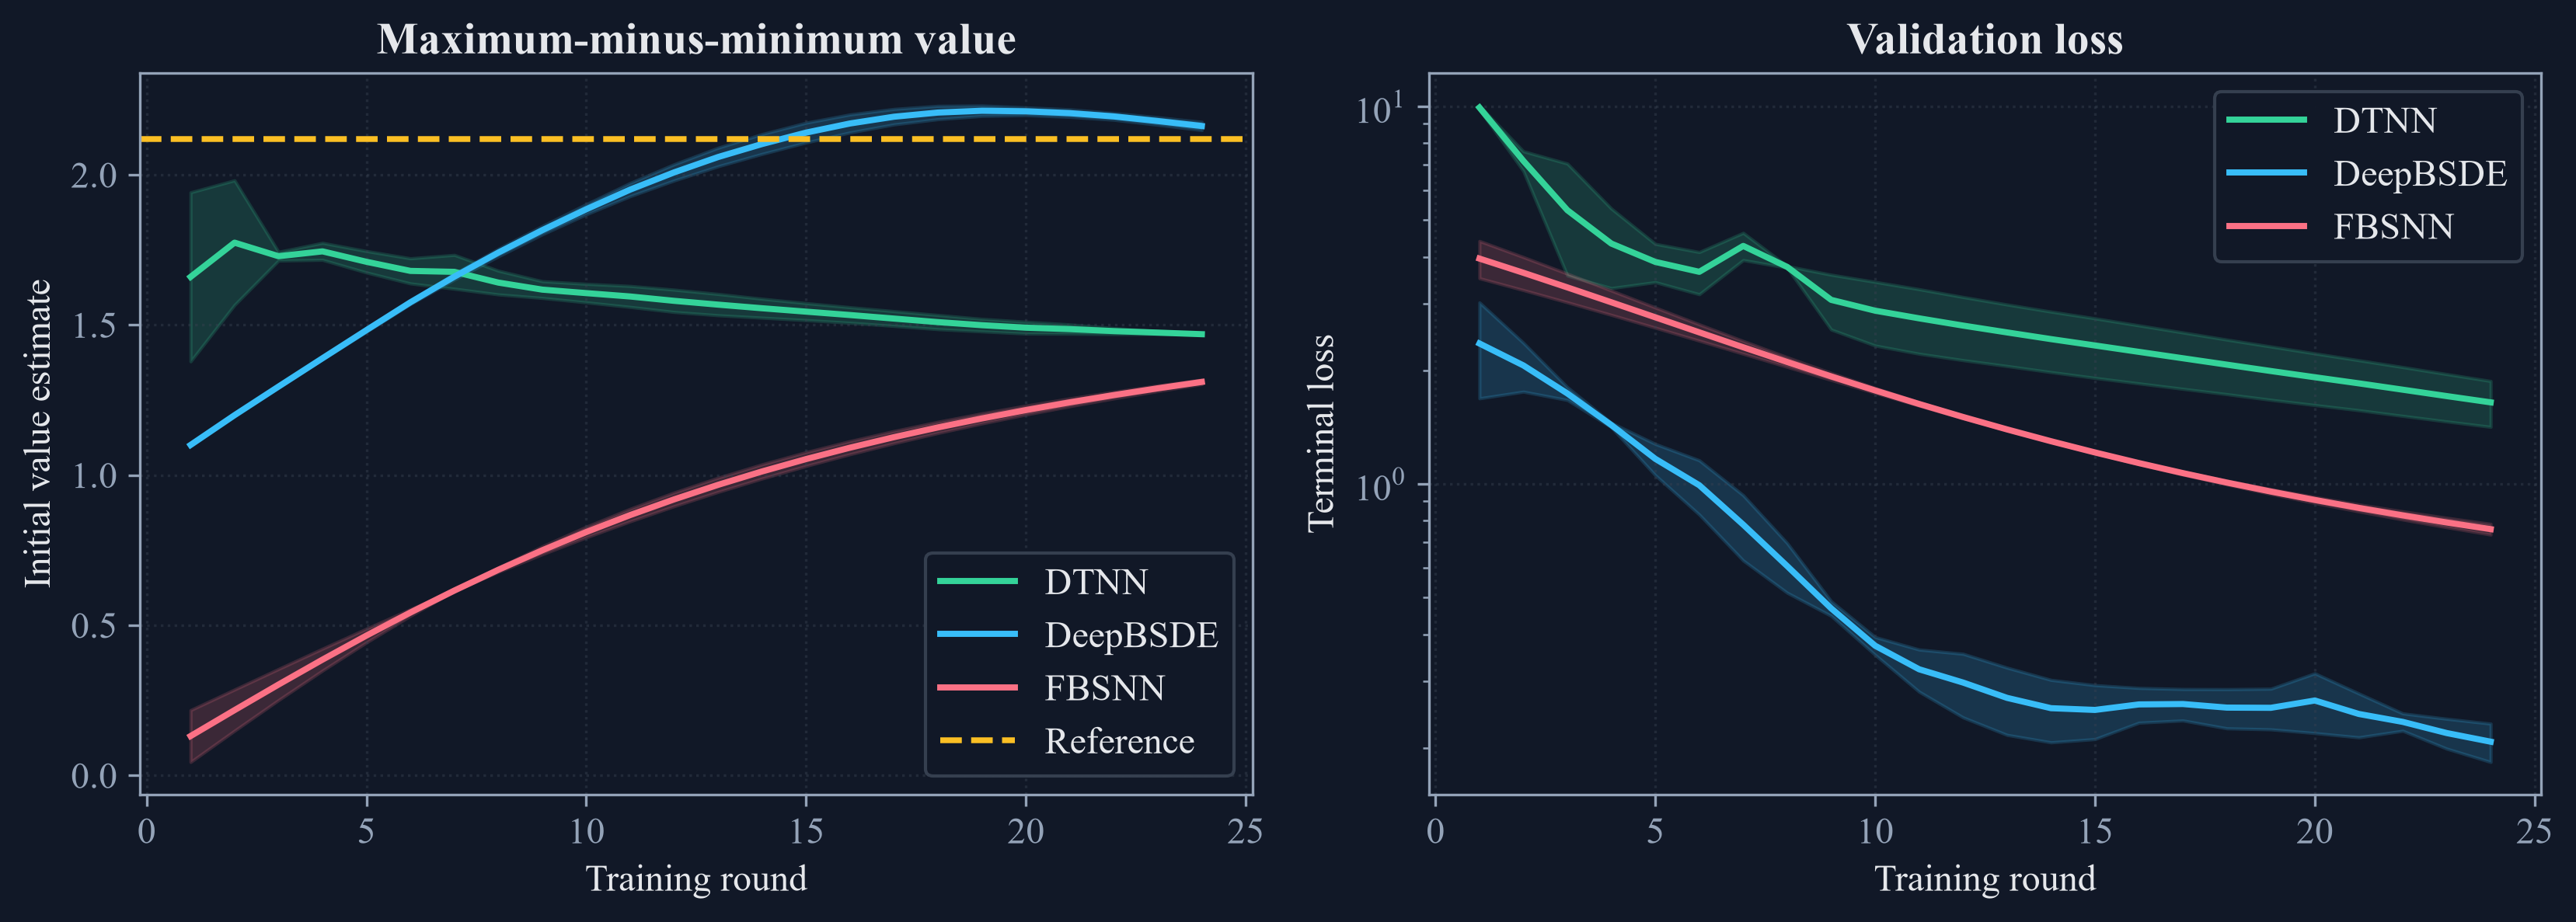

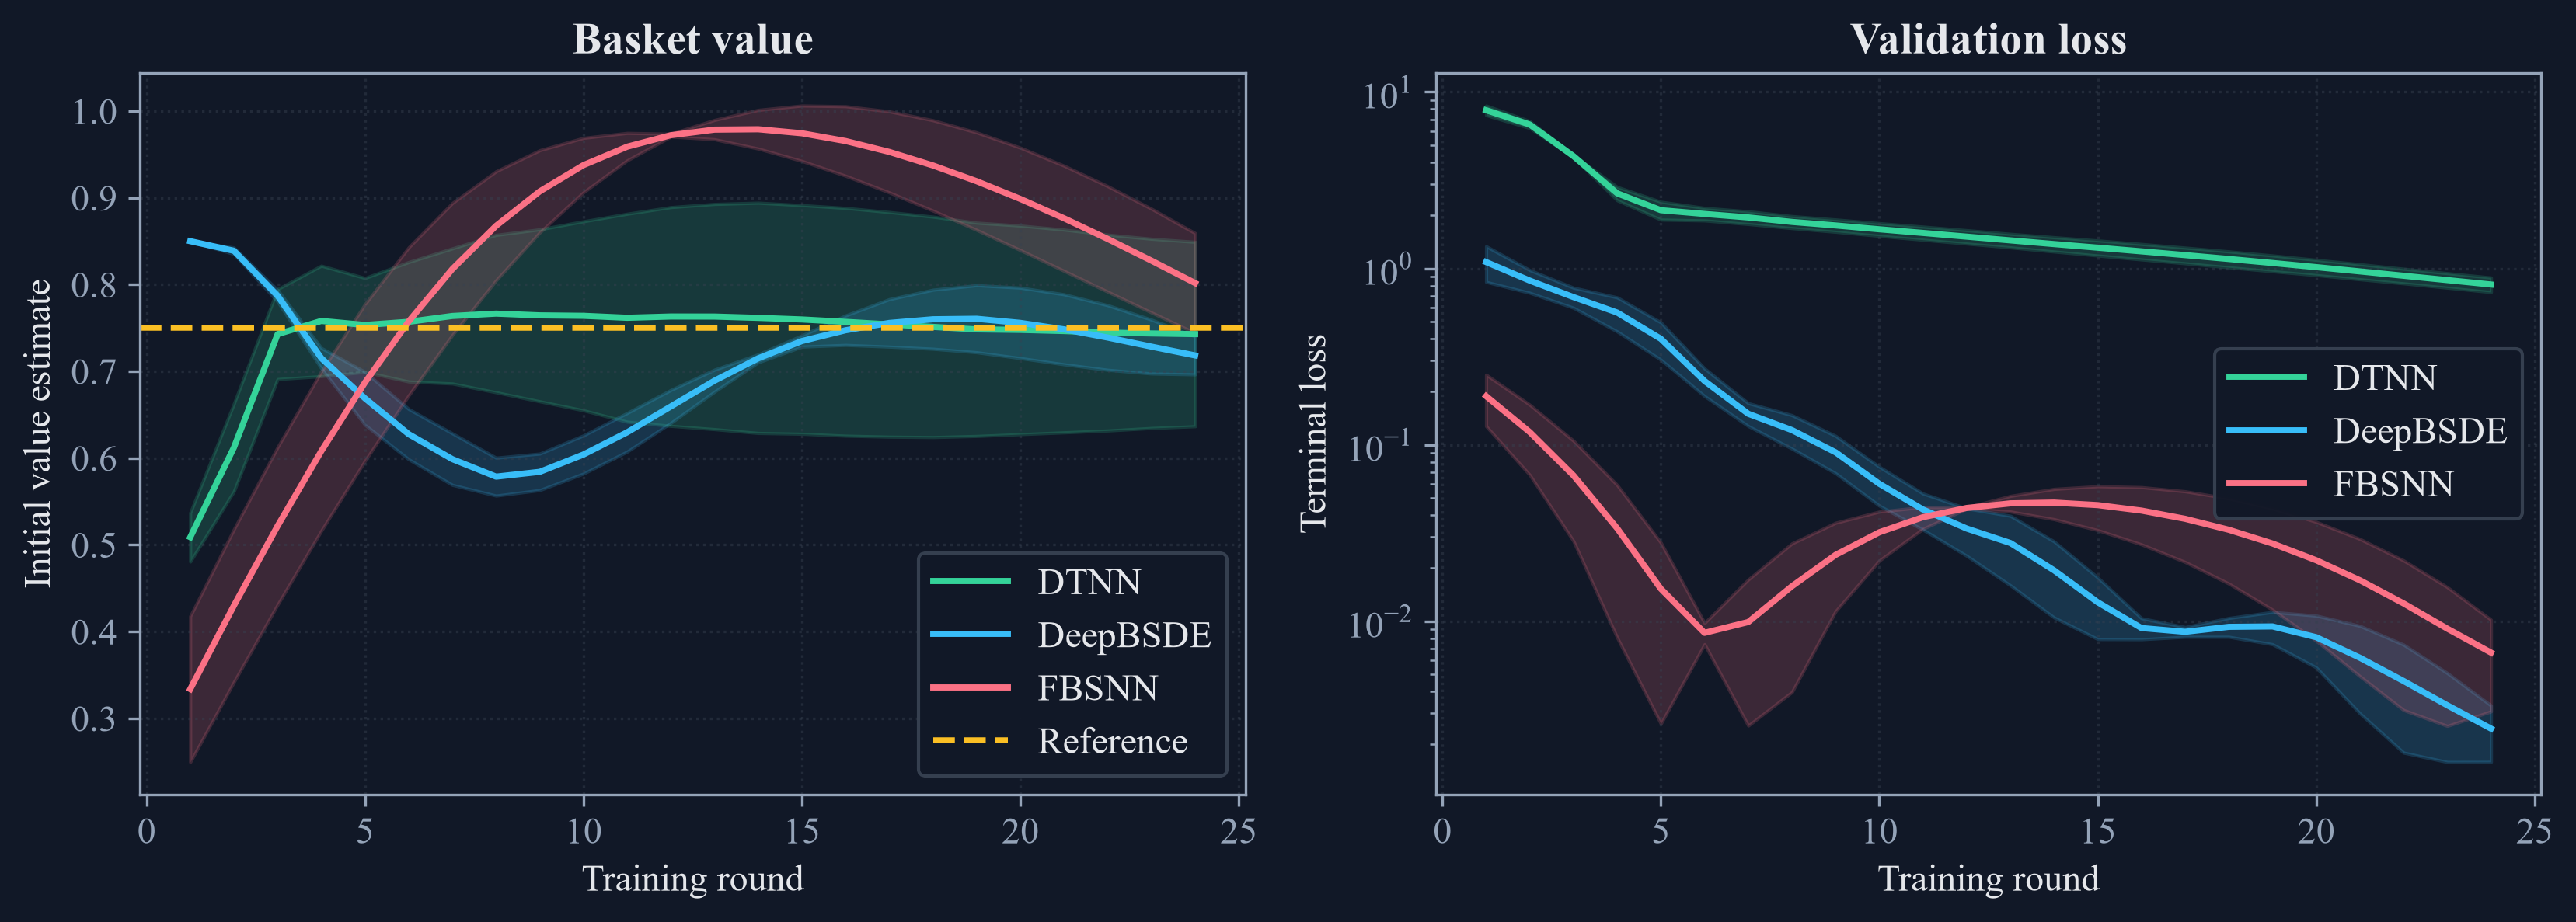

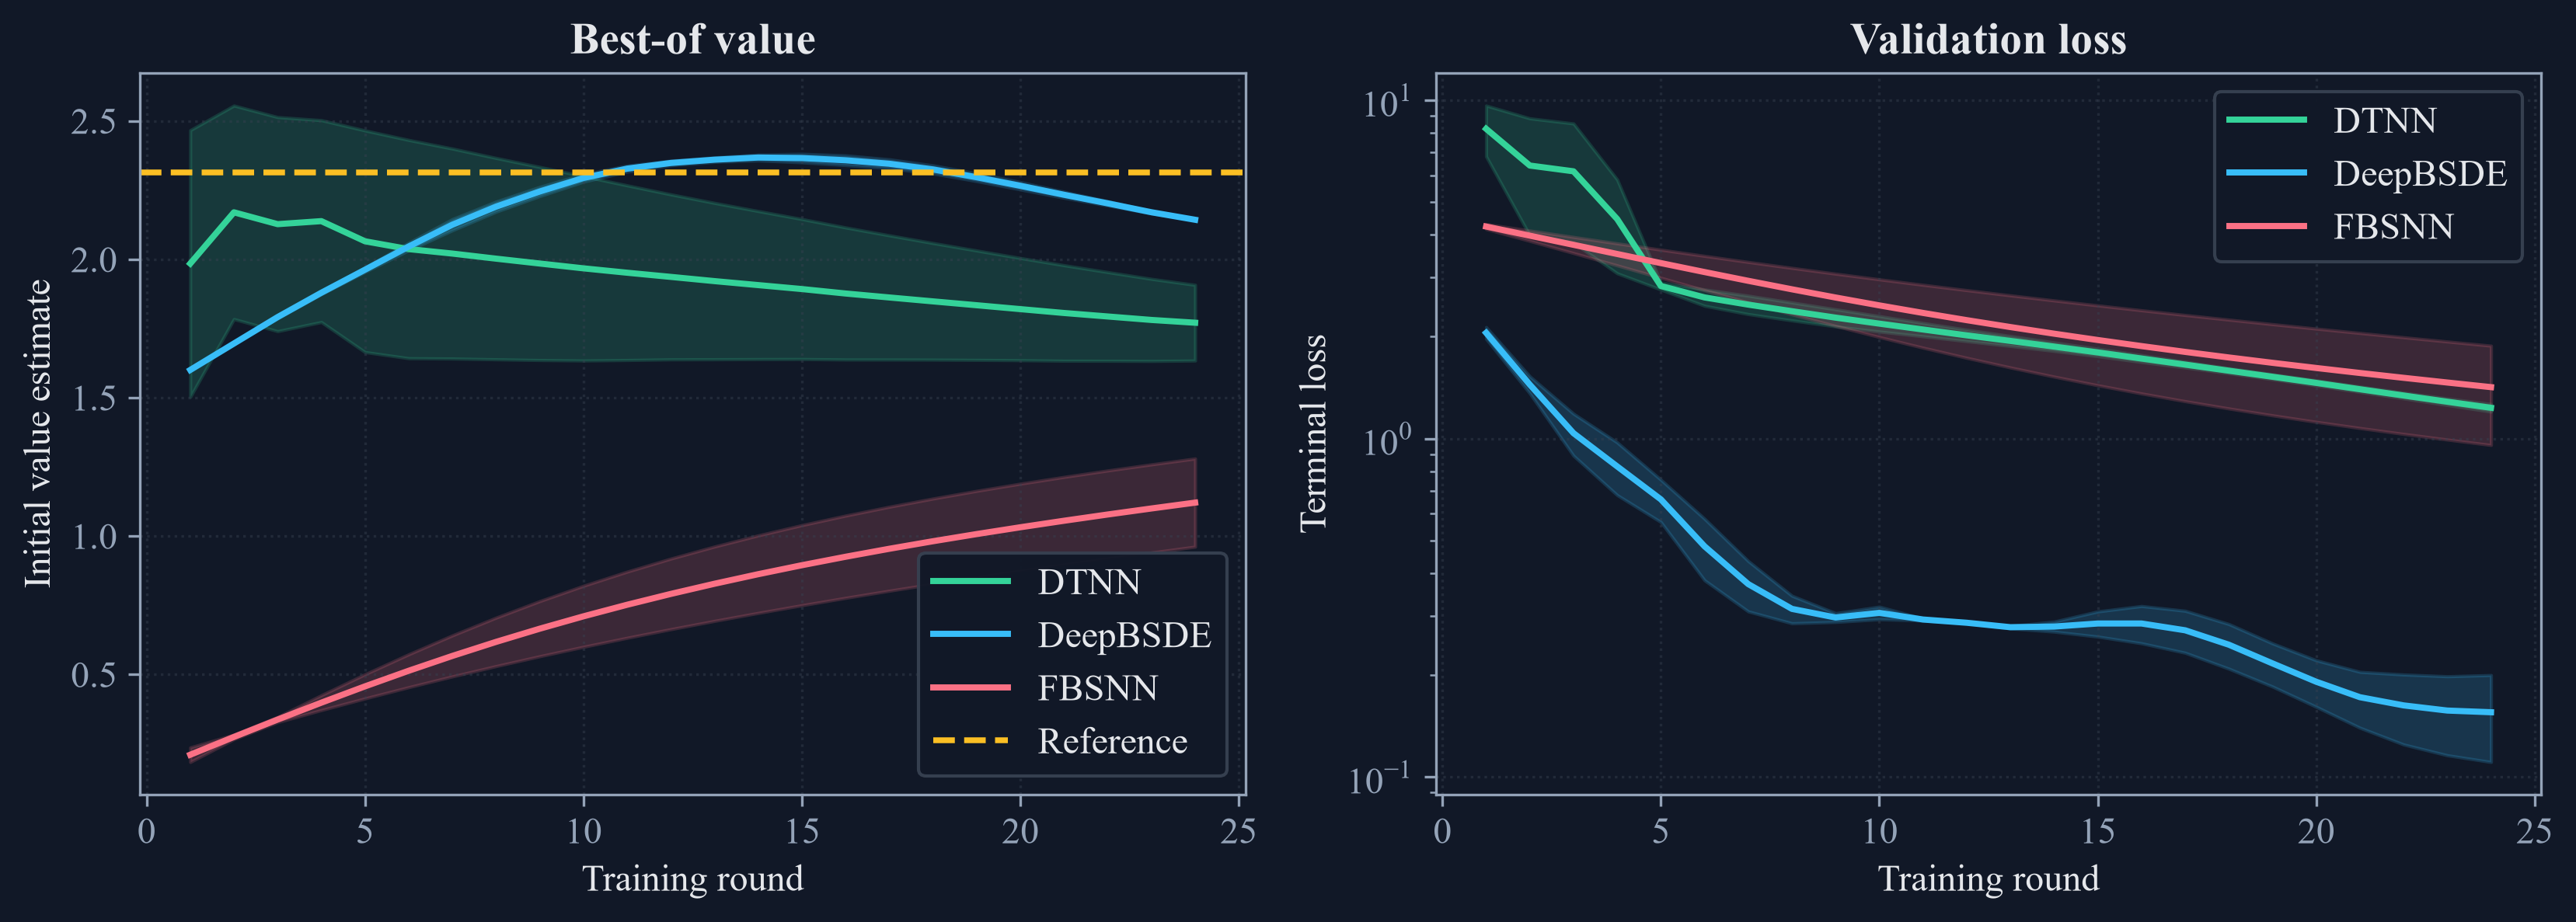

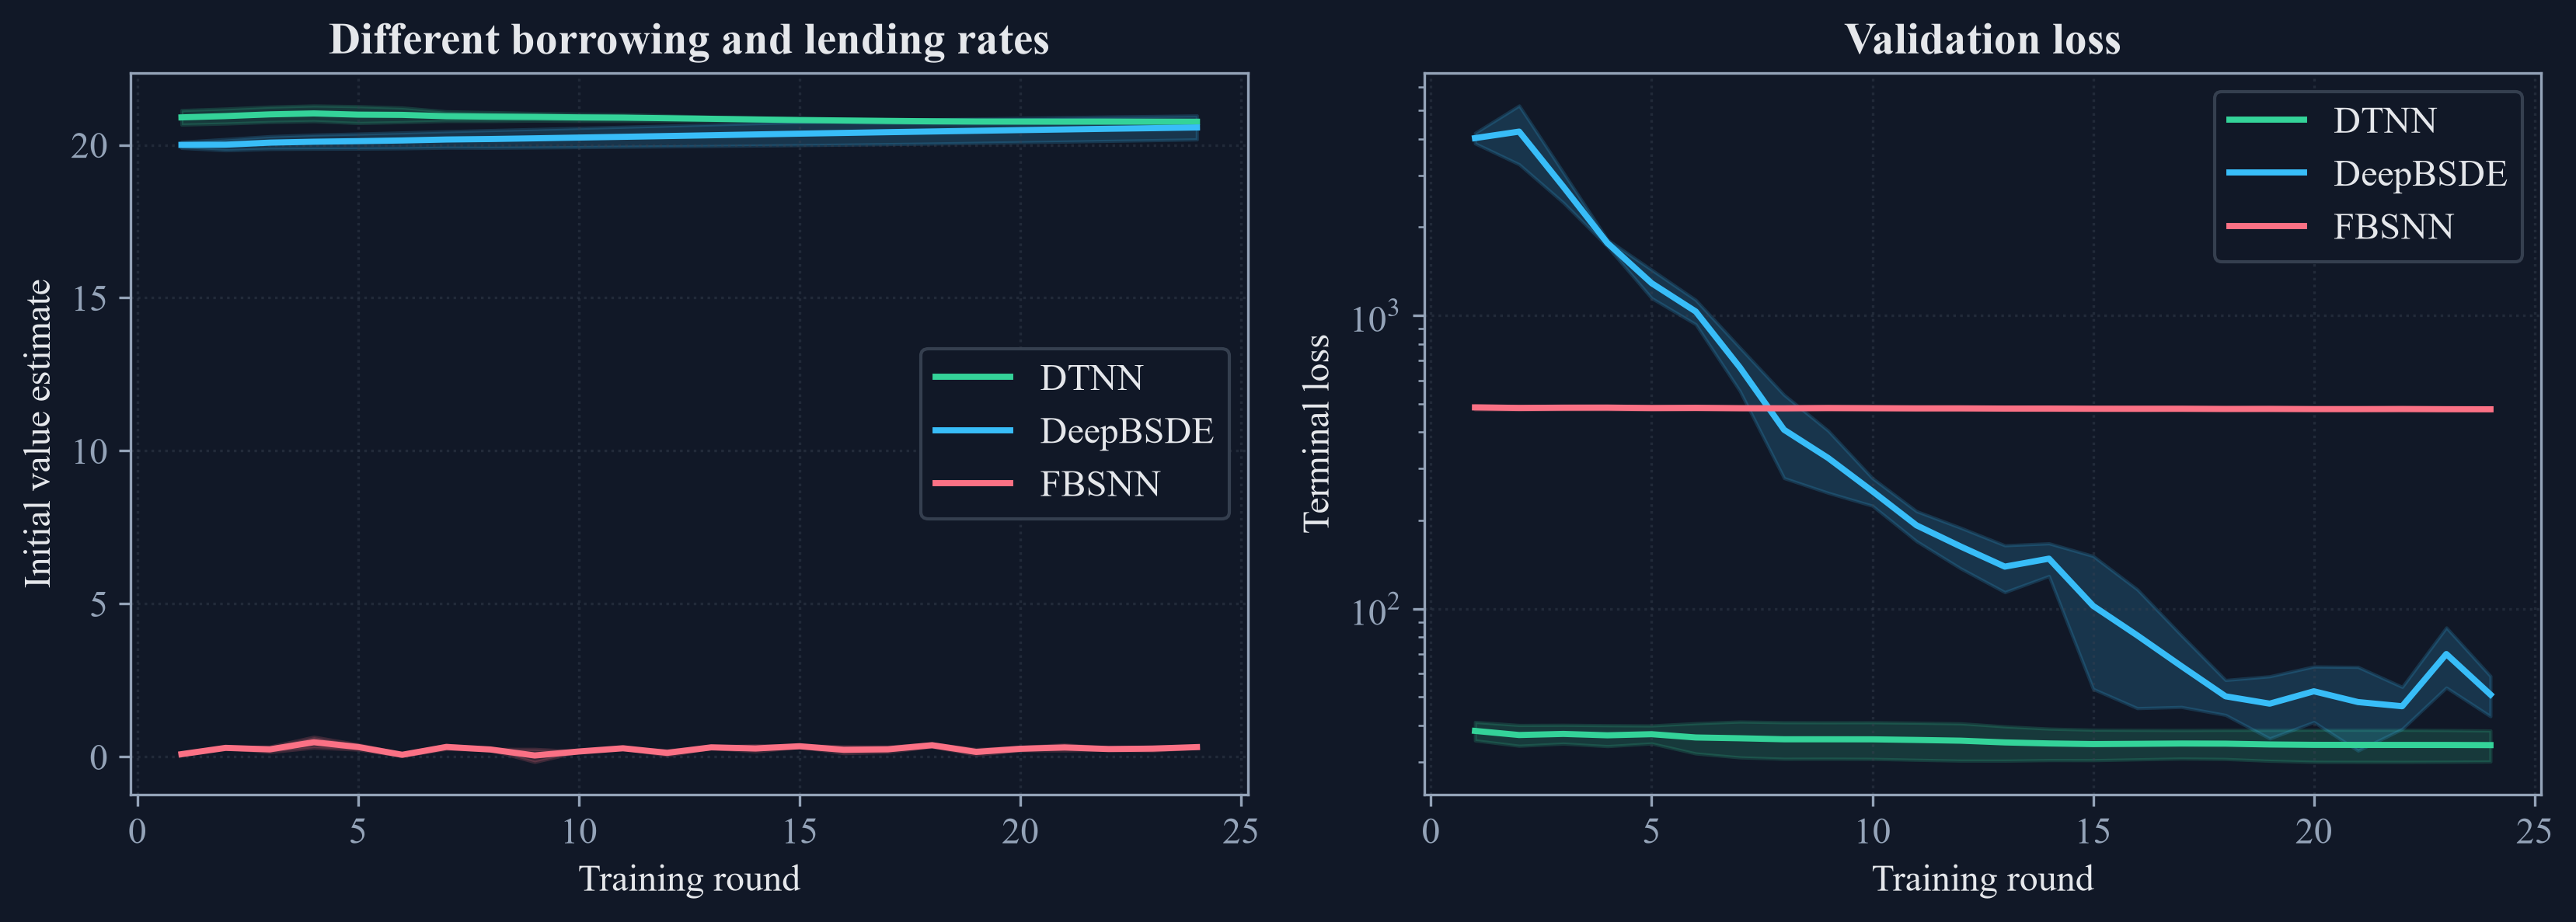

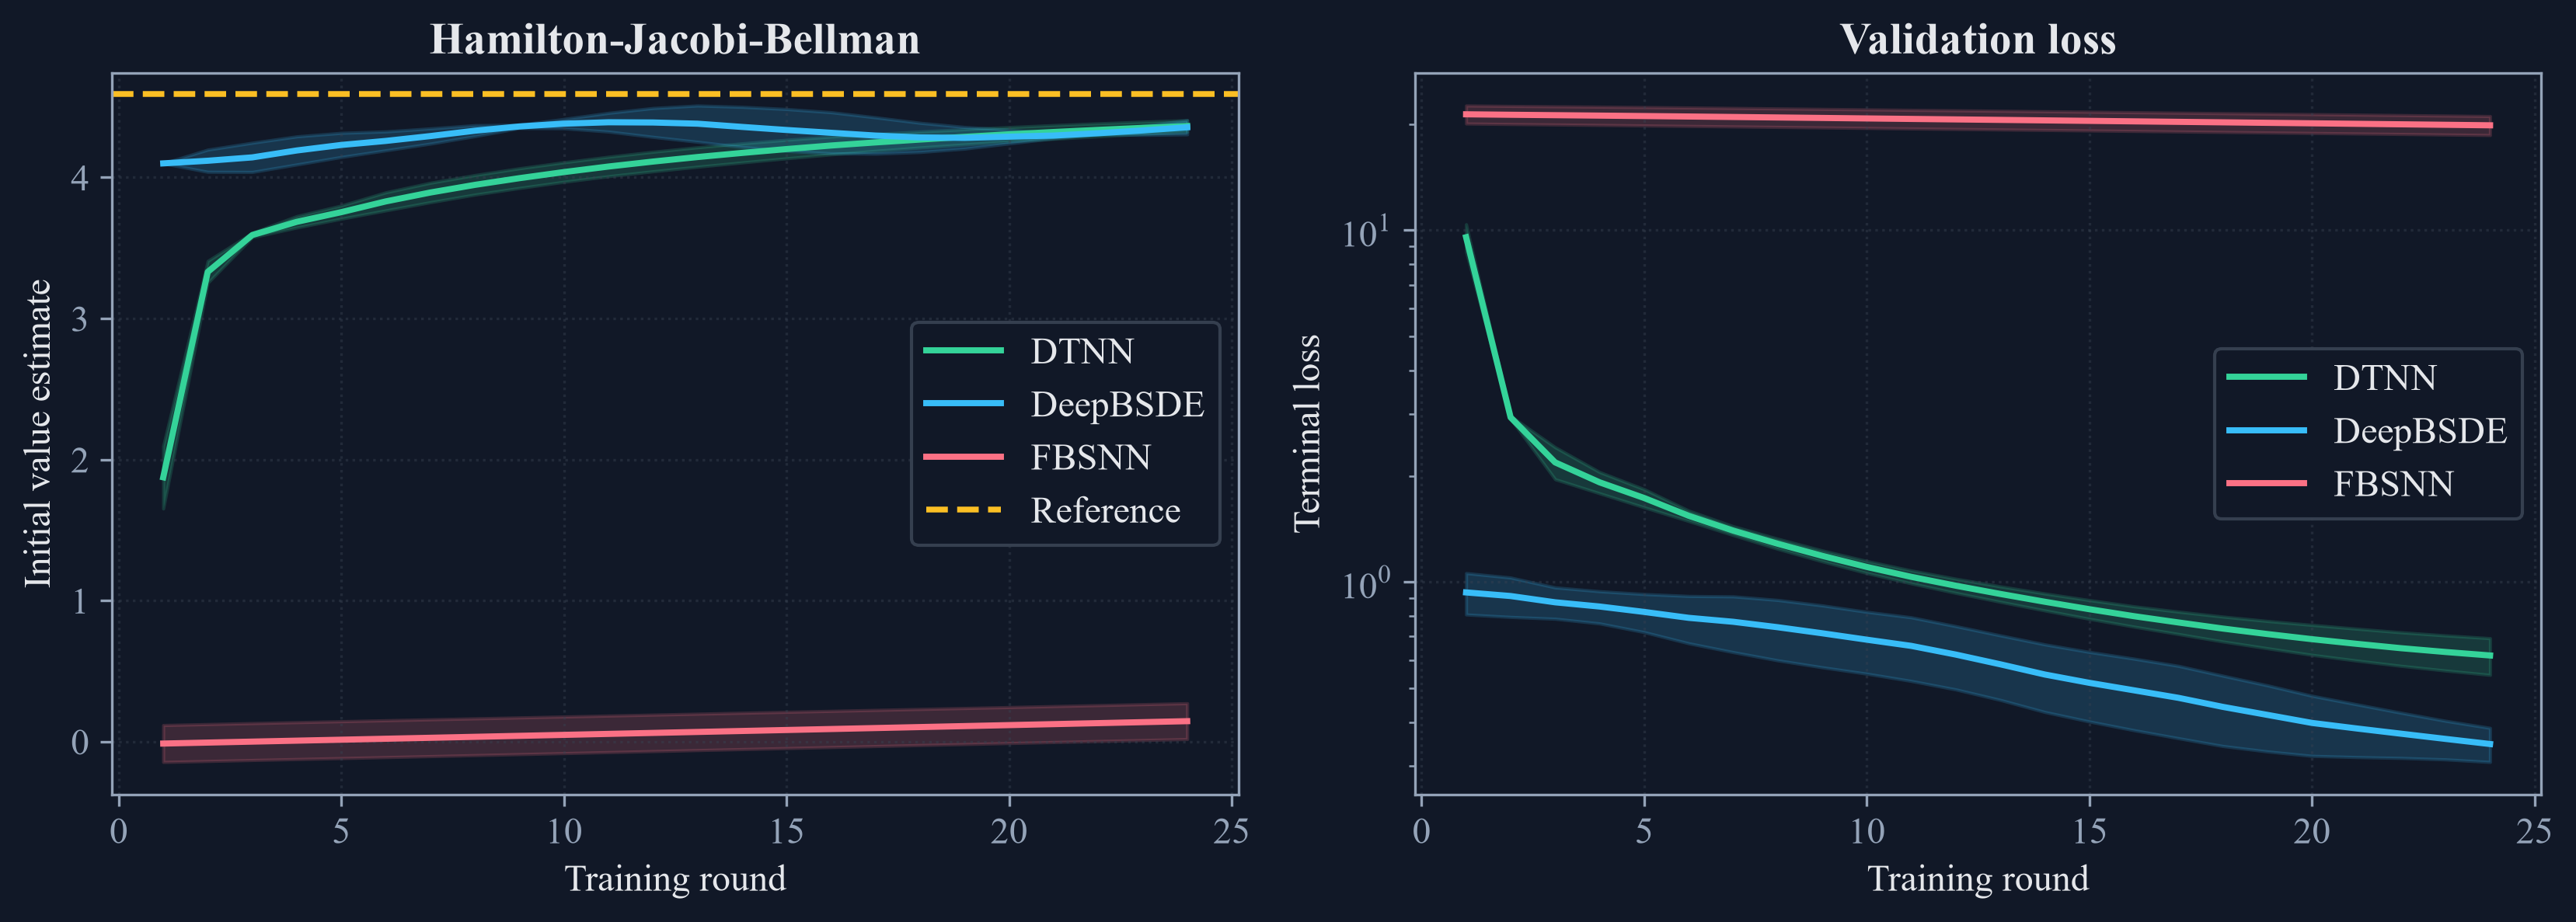

In [4]:
all_histories = []
run_rows = []
for benchmark_position, specification in enumerate(benchmark_specs):
    name = specification["Benchmark"]
    for method in ("DTNN", "DeepBSDE", "FBSNN"):
        for seed in (17, 43):
            pde = specification["Class"]({"dim": 100, "total_time": specification["Final time"], "num_time_interval": 12})
            pde.y_init = specification["Initial guess"]
            result = run_method(pde, method, seed + benchmark_position * 100, 24, 32, 16)
            result.update({"method": method, "seed": seed, "benchmark": name})
            all_histories.append(result)
            reference = reference_values[name]
            run_rows.append({"Benchmark": name, "Method": method, "Seed": seed, "Final initial value": result["estimates"][-1], "Final terminal loss": result["losses"][-1], "Absolute error": abs(result["estimates"][-1] - reference) if np.isfinite(reference) else np.nan, "Relative error": abs(result["estimates"][-1] - reference) / max(abs(reference), 1e-12) if np.isfinite(reference) else np.nan, "Run time seconds": result["seconds"], "Parameters": result["parameters"]})
run_table = pd.DataFrame(run_rows)
summary_rows = []
for name in [item["Benchmark"] for item in benchmark_specs]:
    histories = [item for item in all_histories if item["benchmark"] == name]
    summary = summarize_histories(histories, reference_values[name])
    summary.insert(0, "Benchmark", name)
    summary_rows.append(summary)
summary_table = pd.concat(summary_rows, ignore_index=True)
save_table(run_table, "benchmark_repeated_runs", "Fresh repeated training runs for all seven benchmark families.", "tab:chapter29-benchmark-runs")
save_table(summary_table, "benchmark_method_summary", "Method means, dispersion, run times, and errors across the seven families.", "tab:chapter29-benchmark-summary")
display(run_table)
display(summary_table)

stems = {"Default risk": "default_risk", "Quadratic fixed-volatility value": "quadratic_value", "Maximum-minus-minimum value": "max_min_value", "Basket value": "basket_value", "Best-of value": "best_of_value", "Different borrowing and lending rates": "different_rates", "Hamilton-Jacobi-Bellman": "hjb_100d"}
for name, stem in stems.items():
    histories = [item for item in all_histories if item["benchmark"] == name]
    plot_method_histories(histories, reference_values[name], f"benchmark_{stem}_training", name)

## Testing numerical sensitivity to problem size

,Benchmark,Method,Training rounds,Initial value,Terminal loss,Absolute error
0,Basket value,DTNN,6,0.757072,2.035705,0.068881
1,Basket value,DTNN,12,0.763155,1.513367,0.126066
2,Basket value,DTNN,18,0.751179,1.130872,0.127027
3,Basket value,DTNN,24,0.742911,0.81066,0.106263
4,Basket value,DeepBSDE,6,0.627584,0.229818,0.122416
...,...,...,...,...,...,...
79,Quadratic fixed-volatility value,DeepBSDE,24,70.457531,58.207108,6.647348
80,Quadratic fixed-volatility value,FBSNN,6,0.271103,5436.648926,76.833776
81,Quadratic fixed-volatility value,FBSNN,12,0.623729,5385.234131,76.48115
82,Quadratic fixed-volatility value,FBSNN,18,0.86502,5350.076416,76.239859


,Dimension,Method,Reference value,Initial value,Absolute error,Final terminal loss,Run time seconds
0,5,DTNN,4.317873,4.147643,0.170231,1.590134,0.416006
1,5,DeepBSDE,4.317873,3.882794,0.43508,1.694751,0.083506
2,5,FBSNN,4.317873,0.390996,3.926877,17.029005,0.172149
3,20,DTNN,15.420976,14.459373,0.961602,12.767176,0.388347
4,20,DeepBSDE,15.420976,14.21037,1.210606,10.03632,0.085433
5,20,FBSNN,15.420976,0.65331,14.767665,218.077637,0.17083
6,100,DTNN,77.104879,71.204193,5.900686,112.00502,0.442954
7,100,DeepBSDE,77.104879,75.582108,1.522771,77.556915,0.100898
8,100,FBSNN,77.104879,1.309023,75.795856,5282.538086,0.188018


,Time intervals,Step length,Method,Reference value,Initial value,Absolute error,Final terminal loss,Run time seconds
0,6,0.166667,DTNN,15.420976,14.151635,1.269341,9.030781,0.204394
1,6,0.166667,DeepBSDE,15.420976,14.32274,1.098236,7.034869,0.04226
2,6,0.166667,FBSNN,15.420976,0.283499,15.137477,211.214432,0.08821
3,12,0.083333,DTNN,15.420976,14.109735,1.31124,13.290215,0.391794
4,12,0.083333,DeepBSDE,15.420976,14.253952,1.167024,11.034725,0.082031
5,12,0.083333,FBSNN,15.420976,0.381802,15.039174,217.319717,0.170401
6,24,0.041667,DTNN,15.420976,14.073519,1.347457,12.176495,0.770084
7,24,0.041667,DeepBSDE,15.420976,14.333322,1.087654,9.549349,0.157594
8,24,0.041667,FBSNN,15.420976,0.136741,15.284235,219.325974,0.392508


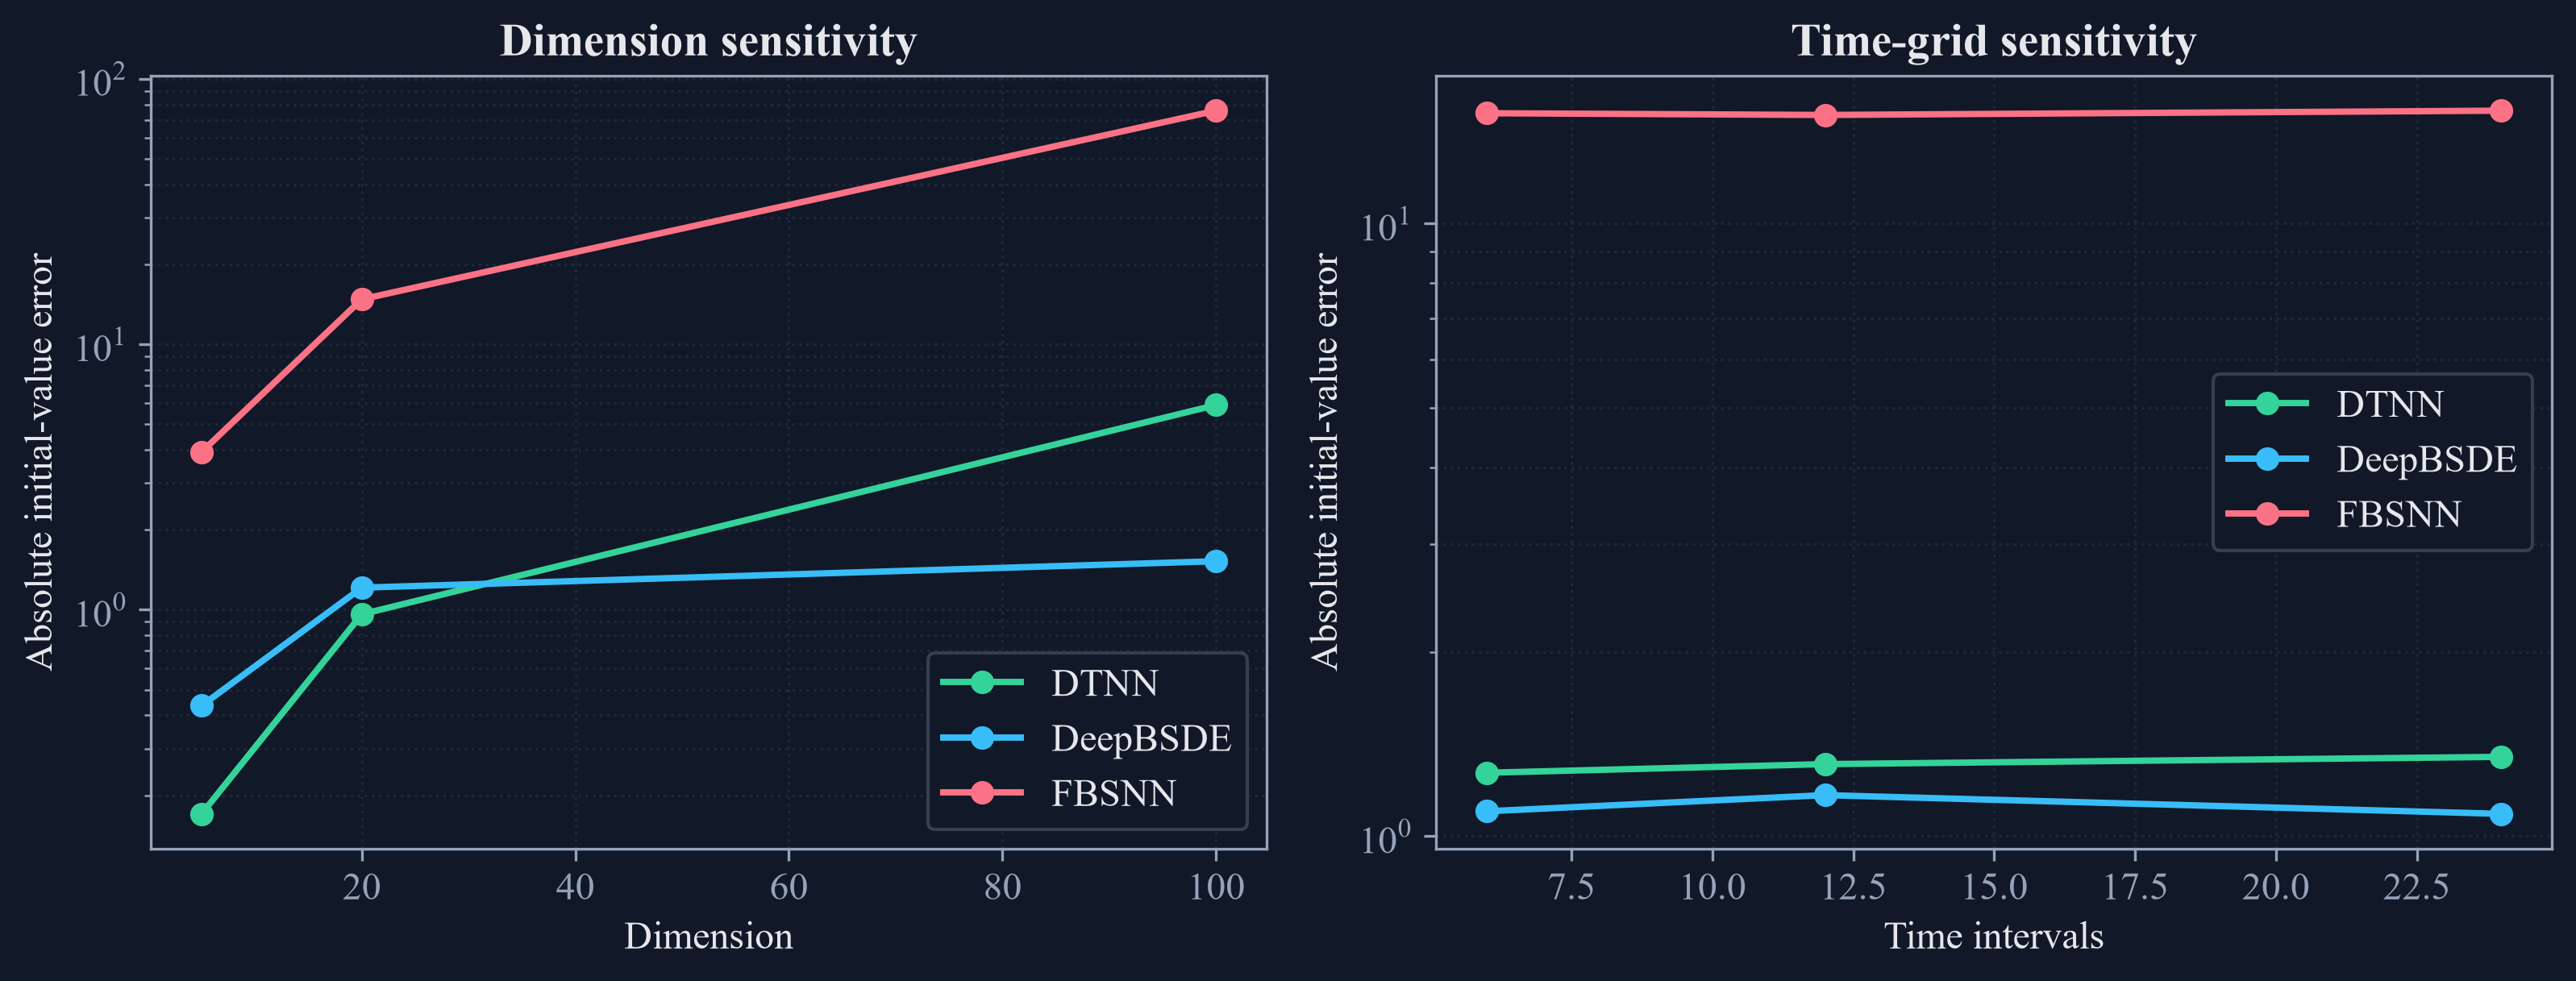

In [5]:
budget_rows = []
for item in all_histories:
    for checkpoint in (6, 12, 18, 24):
        reference = reference_values[item["benchmark"]]
        budget_rows.append({"Benchmark": item["benchmark"], "Method": item["method"], "Seed": item["seed"], "Training rounds": checkpoint, "Initial value": item["estimates"][checkpoint - 1], "Terminal loss": item["losses"][checkpoint - 1], "Absolute error": abs(item["estimates"][checkpoint - 1] - reference) if np.isfinite(reference) else np.nan})
budget_table = pd.DataFrame(budget_rows).groupby(["Benchmark", "Method", "Training rounds"], as_index=False).agg({"Initial value": "mean", "Terminal loss": "mean", "Absolute error": "mean"})
save_table(budget_table, "benchmark_budget_sensitivity", "Mean estimates and losses as the training budget grows.", "tab:chapter29-budget-sensitivity")
display(budget_table)

dimension_rows = []
for dimension in (5, 20, 100):
    pde = BlackScholesBarenblatt({"dim": dimension, "total_time": 1.0, "num_time_interval": 12})
    reference = float(np.exp((pde.rate + pde.sigma**2) * pde.total_time) * np.sum(np.asarray(pde.x_init)**2))
    for method in ("DTNN", "DeepBSDE", "FBSNN"):
        pde = BlackScholesBarenblatt({"dim": dimension, "total_time": 1.0, "num_time_interval": 12})
        pde.y_init = reference
        result = run_method(pde, method, 3000 + dimension, 16, 32, 16)
        dimension_rows.append({"Dimension": dimension, "Method": method, "Reference value": reference, "Initial value": result["estimates"][-1], "Absolute error": abs(result["estimates"][-1] - reference), "Final terminal loss": result["losses"][-1], "Run time seconds": result["seconds"]})
dimension_table = pd.DataFrame(dimension_rows)
save_table(dimension_table, "benchmark_dimension_sensitivity", "Quadratic fixed-volatility results at three dimensions.", "tab:chapter29-dimension-sensitivity")
display(dimension_table)

grid_rows = []
for intervals in (6, 12, 24):
    pde = BlackScholesBarenblatt({"dim": 20, "total_time": 1.0, "num_time_interval": intervals})
    reference = float(np.exp((pde.rate + pde.sigma**2) * pde.total_time) * np.sum(np.asarray(pde.x_init)**2))
    for method in ("DTNN", "DeepBSDE", "FBSNN"):
        pde = BlackScholesBarenblatt({"dim": 20, "total_time": 1.0, "num_time_interval": intervals})
        pde.y_init = reference
        result = run_method(pde, method, 3100 + intervals, 16, 32, 16)
        grid_rows.append({"Time intervals": intervals, "Step length": pde.delta_t, "Method": method, "Reference value": reference, "Initial value": result["estimates"][-1], "Absolute error": abs(result["estimates"][-1] - reference), "Final terminal loss": result["losses"][-1], "Run time seconds": result["seconds"]})
grid_table = pd.DataFrame(grid_rows)
save_table(grid_table, "benchmark_time_grid_sensitivity", "Quadratic fixed-volatility results on three time grids.", "tab:chapter29-grid-sensitivity")
display(grid_table)

color_map = {"DTNN": palette["green"], "DeepBSDE": palette["cyan"], "FBSNN": palette["rose"]}
figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.2))
for method, group in dimension_table.groupby("Method"):
    axes[0].plot(group["Dimension"], group["Absolute error"], marker="o", linewidth=1.9, color=color_map[method], label=method)
for method, group in grid_table.groupby("Method"):
    axes[1].plot(group["Time intervals"], group["Absolute error"], marker="o", linewidth=1.9, color=color_map[method], label=method)
axes[0].set_xlabel("Dimension")
axes[0].set_ylabel("Absolute initial-value error")
axes[0].set_title("Dimension sensitivity")
axes[1].set_xlabel("Time intervals")
axes[1].set_ylabel("Absolute initial-value error")
axes[1].set_title("Time-grid sensitivity")
for axis in axes:
    axis.set_yscale("log")
    axis.grid(True, which="both", alpha=0.4)
    axis.legend()
figure.tight_layout()
save_figure(figure, "dimension_and_grid_sensitivity")

## Checking terminal-value helpers against references

,Generated terminal states,Reference estimate,Estimated standard error
0,2000,2.298575,0.009926
1,8000,2.299827,0.00501
2,32000,2.31121,0.002574
3,80000,2.314555,0.001622


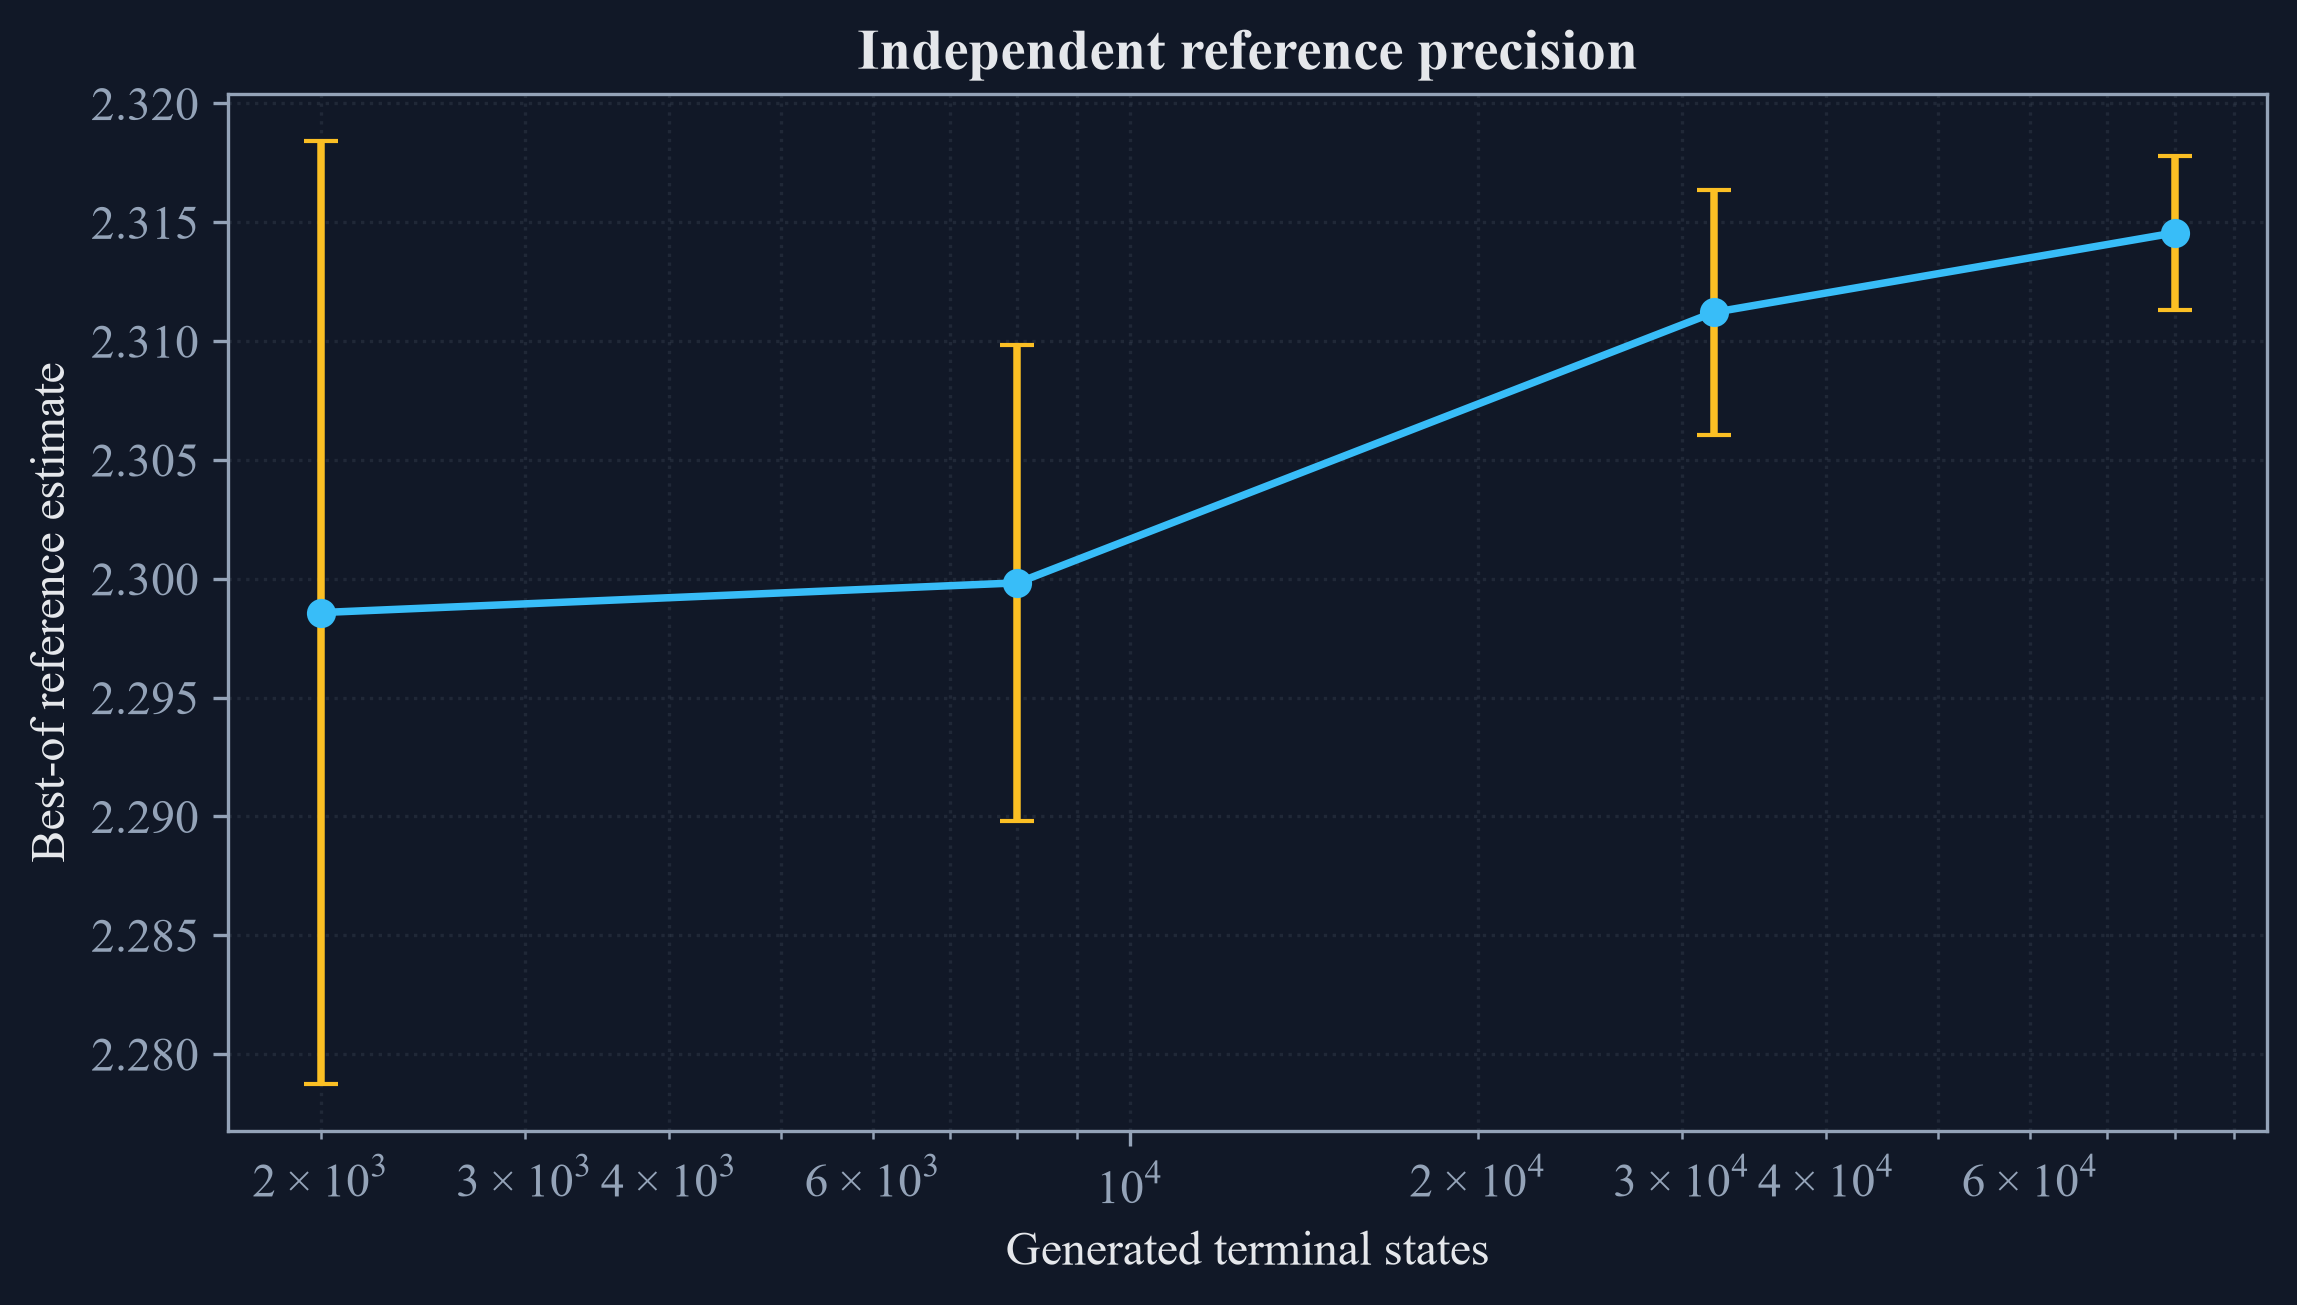

,Case,Direct terminal value,Multi-sample helper value,Values agree
0,Maximum state 160,20,40,False
1,Maximum state 130,10,10,True


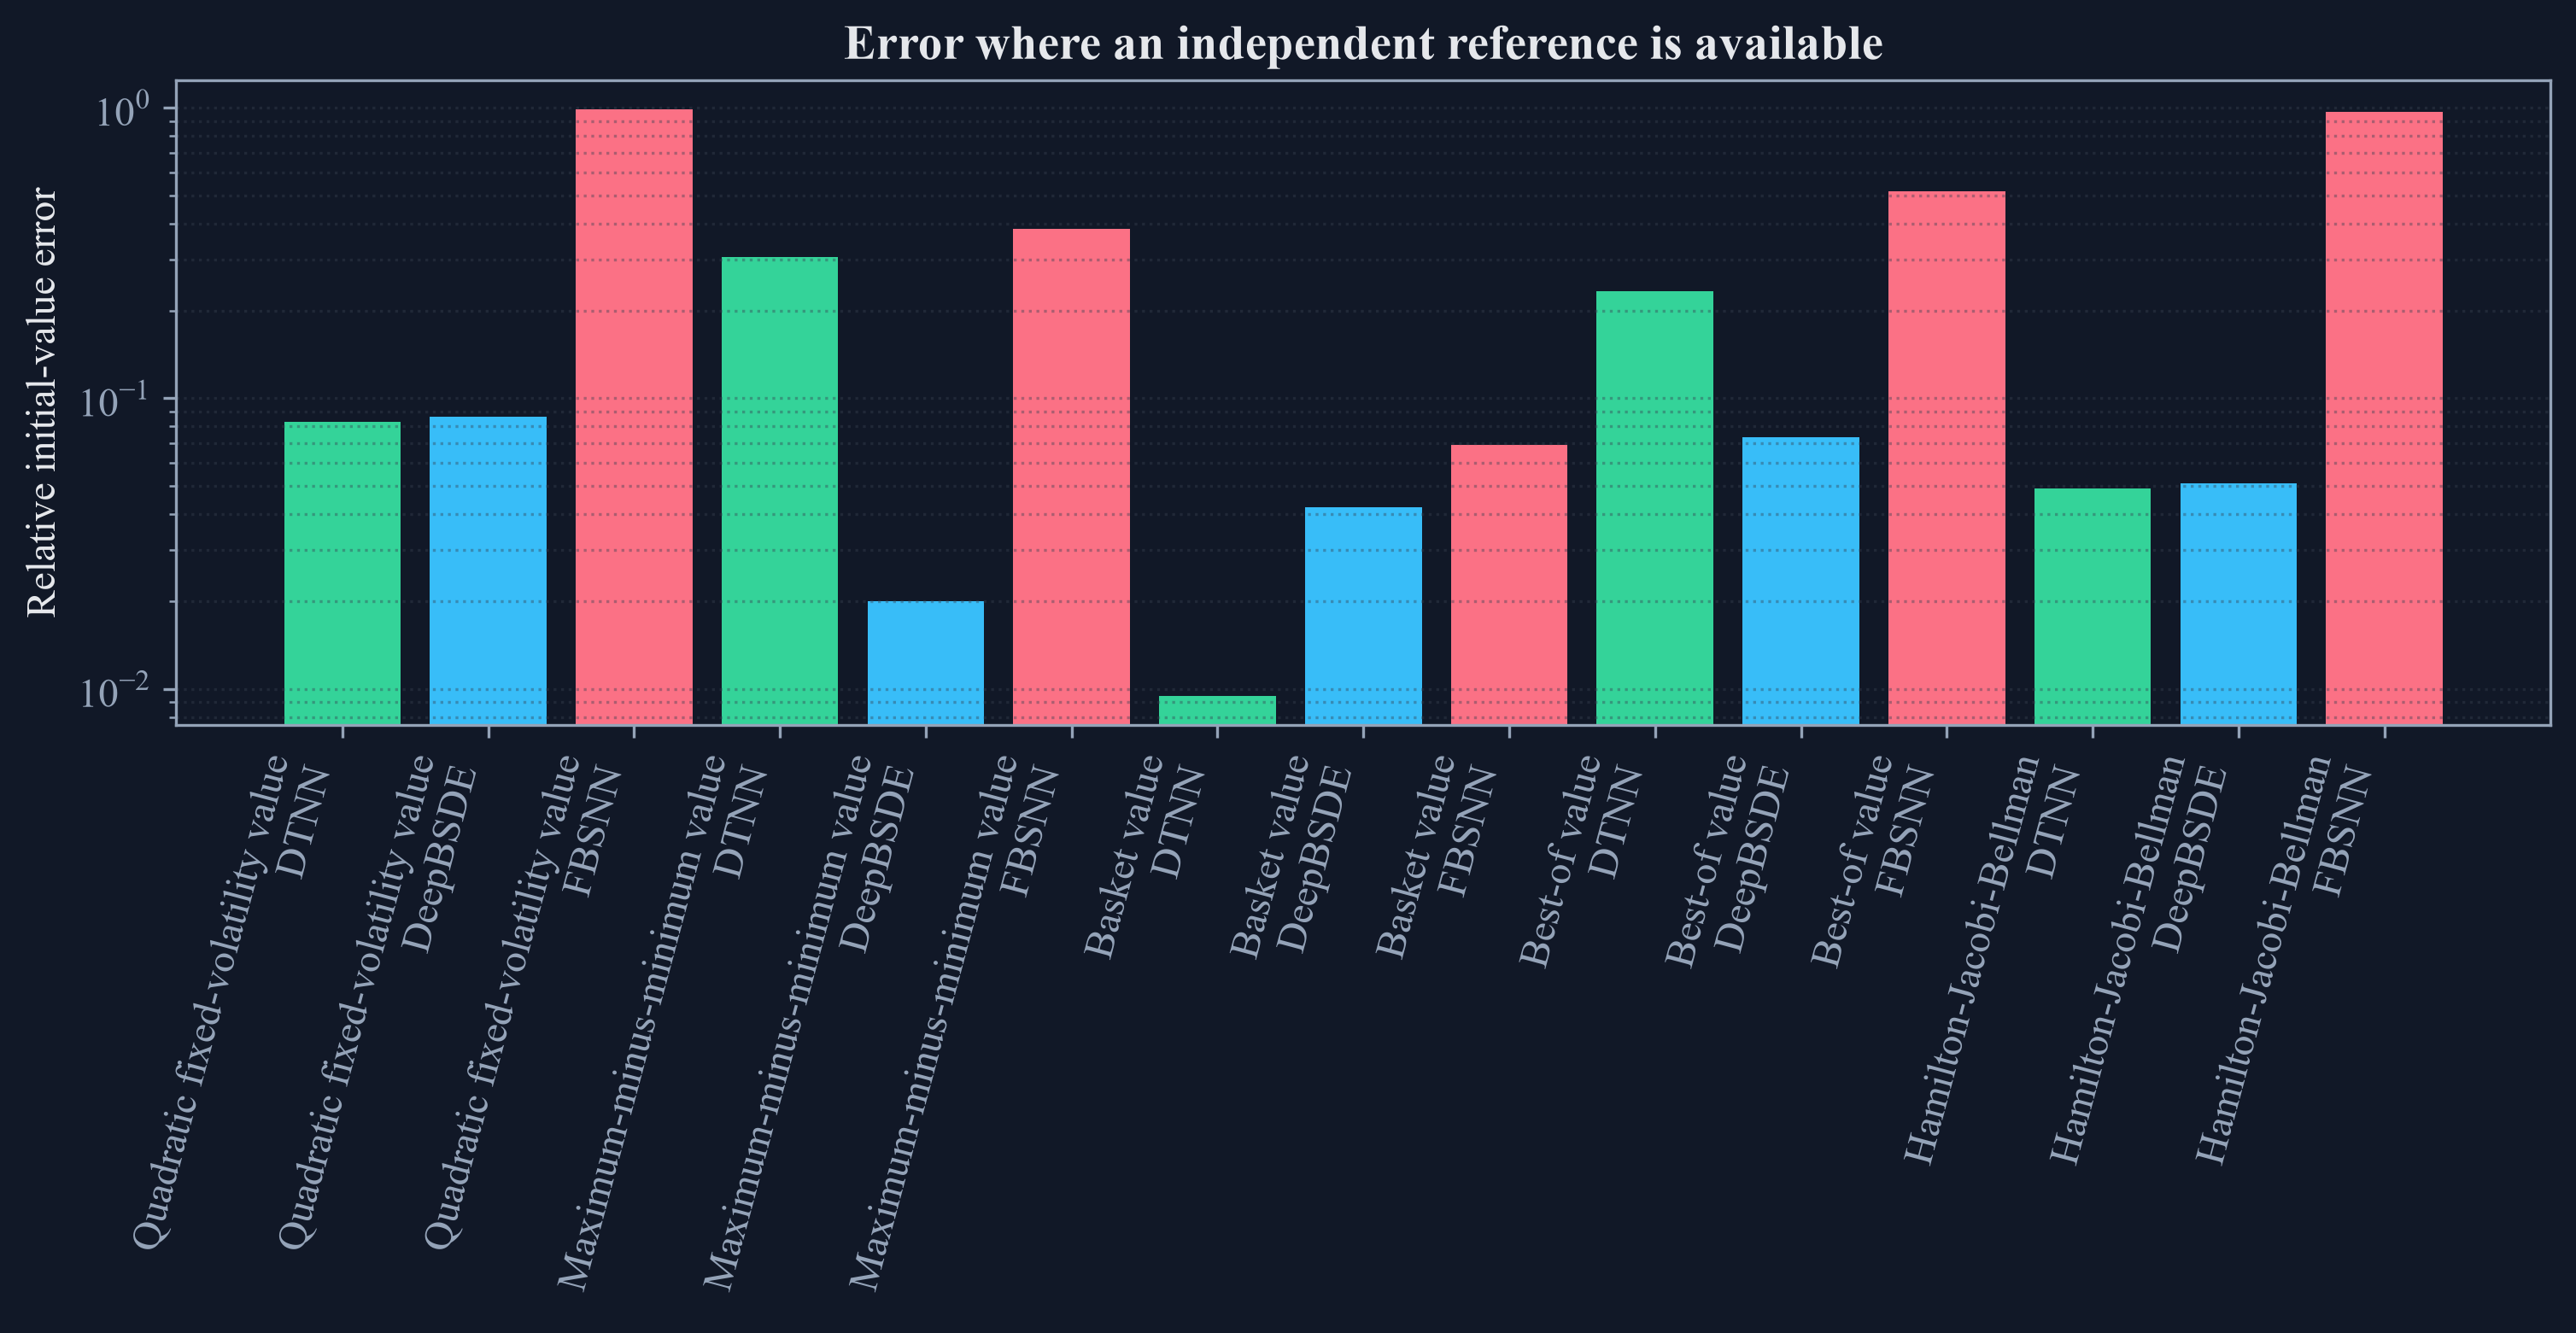

In [6]:
convergence_rows = []
for draws in (2000, 8000, 32000, 80000):
    pde = BlackScholesBarenblattBestOf({"dim": 100, "total_time": 1.0, "num_time_interval": 12})
    value, standard_error = discounted_lognormal_reference(pde, "Best-of value", draws, 3200 + draws)
    convergence_rows.append({"Generated terminal states": draws, "Reference estimate": value, "Estimated standard error": standard_error})
convergence_table = pd.DataFrame(convergence_rows)
save_table(convergence_table, "reference_monte_carlo_convergence", "Best-of reference estimate as the number of generated terminal states grows.", "tab:chapter29-reference-convergence")
display(convergence_table)

figure, axis = plt.subplots(figsize=(7.8, 4.5))
axis.errorbar(convergence_table["Generated terminal states"], convergence_table["Reference estimate"], yerr=2.0 * convergence_table["Estimated standard error"], marker="o", color=palette["cyan"], ecolor=palette["amber"], capsize=4, linewidth=1.8)
axis.set_xscale("log")
axis.set_xlabel("Generated terminal states")
axis.set_ylabel("Best-of reference estimate")
axis.set_title("Independent reference precision")
axis.grid(True, which="both", alpha=0.4)
figure.tight_layout()
save_figure(figure, "reference_monte_carlo_convergence")

helper_pde = PricingDiffRate({"dim": 6, "total_time": 0.5, "num_time_interval": 12})
test_state = torch.tensor([[160.0, 90.0, 80.0, 70.0, 60.0, 50.0], [130.0, 120.0, 110.0, 100.0, 90.0, 80.0]], dtype=torch.float32)
direct = helper_pde.terminal(helper_pde.total_time, test_state).reshape(-1)
helper = helper_pde.terminal_for_sample(test_state.unsqueeze(0)).reshape(-1)
helper_table = pd.DataFrame({"Case": ["Maximum state 160", "Maximum state 130"], "Direct terminal value": direct.numpy(), "Multi-sample helper value": helper.numpy(), "Values agree": torch.isclose(direct, helper).numpy()})
save_table(helper_table, "different_rate_terminal_helper", "The released different-rate terminal helper omits the second payoff term above 150.", "tab:chapter29-different-rate-helper")
display(helper_table)

available = summary_table.dropna(subset=["Absolute error"]).copy()
figure, axis = plt.subplots(figsize=(10.2, 5.3))
positions = np.arange(len(available))
colors = [color_map[item] for item in available["Method"]]
axis.bar(positions, available["Relative error"], color=colors)
axis.set_yscale("log")
axis.set_xticks(positions)
axis.set_xticklabels([f"{row.Benchmark}\n{row.Method}" for row in available.itertuples()], rotation=75, ha="right")
axis.set_ylabel("Relative initial-value error")
axis.set_title("Error where an independent reference is available")
axis.grid(True, axis="y", which="both", alpha=0.4)
figure.tight_layout()
save_figure(figure, "benchmark_relative_errors")

## Tests

In [7]:
assert len(benchmark_specs) == 7
assert len(run_table) == 42
assert set(run_table["Method"]) == {"DTNN", "DeepBSDE", "FBSNN"}
assert set(run_table["Benchmark"]) == set(design_table["Benchmark"])
assert np.isfinite(run_table["Final initial value"]).all()
assert np.isfinite(run_table["Final terminal loss"]).all()
assert len(reference_table.dropna(subset=["Reference value"])) == 5
quadratic_reference = reference_values["Quadratic fixed-volatility value"]
assert np.isclose(quadratic_reference, np.exp(0.21) * 62.5)
assert np.isclose(reference_values["Basket value"], 0.75)
assert len(dimension_table) == 9 and len(grid_table) == 9
assert helper_table["Values agree"].tolist() == [False, True]
assert convergence_table["Estimated standard error"].iloc[-1] < convergence_table["Estimated standard error"].iloc[0]
assert all(finite_sequence(item["losses"]) and finite_sequence(item["estimates"]) for item in all_histories)
display(pd.DataFrame({"Test": ["Seven families", "Three methods", "Two seeds", "Finite estimates", "Five independent references", "Quadratic formula", "Basket formula", "Dimension checks", "Time-grid checks", "Different-rate helper mismatch", "Reference precision"], "Passed": [True, True, True, True, True, True, True, True, True, True, True]}))

,Test,Passed
0,Seven families,True
1,Three methods,True
2,Two seeds,True
3,Finite estimates,True
4,Five independent references,True
5,Quadratic formula,True
6,Basket formula,True
7,Dimension checks,True
8,Time-grid checks,True
9,Different-rate helper mismatch,True
